# Sistema Híbrido de IA — Práctica 1
### Sistema de recomendación de universidades para intercambio académico
Introducción a la IA — sistemas expertos (Experta), lógica difusa (Scikit-Fuzzy) y ontologías (RDFLib + OWL-RL).

**Problema.** Un estudiante de la UNAL quiere saber a qué convocatorias de intercambio (nacionales o internacionales) puede aplicar y cuáles le convienen más. Cada oferta tiene requisitos duros (fecha de cierre, cupos, nivel de estudios, área, idioma) y otros criterios graduales (qué tan bueno es su promedio, qué tan cerca está su idioma del requerido, qué tan competida está la oferta por el número de cupos).

**Solución híbrida — flujo general del programa:**

```
 ontologia.ttl ──► RDFLib ──► OWL-RL DeductiveClosure(RDFS_Semantics) ──► grafo razonado
                                                                            │
                         ┌──────────────────────────────────────────────────┤
                         ▼                                                  ▼
          Lógica difusa (Scikit-Fuzzy)                     Traductor Ontología → Sistema Experto
   lee del grafo promedio, idiomas y cupos,               recorre TODOS los triples del grafo y
   calcula idoneidad (Mamdani + centroide)                declara un Fact por cada uno
                         │                                                  │
                         └──── ResultadoDifuso(oferta, puntaje, categoria) ─┤
                                                                            ▼
                                             Sistema experto (Experta, 30 reglas, 7 niveles de salience)
                                             filtra, evalúa y genera Recomendacion / Advertencia / Nota
```

| Módulo | Celdas | Qué hace |
|---|---|---|
| **1. Ontología** | 1.1 – 1.3 | Define el dominio en RDF/RDFS (Turtle), razona con OWL-RL y dibuja el diagrama de clases |
| **2. Lógica difusa** | 2.1 | Variables, funciones de pertenencia, modificadores, 10 reglas y defuzzificación por centroide |
| **3. Sistema experto** | 3.1 – 3.6 | Clases de hechos, traductor, motor de reglas, escenarios, pruebas y mecanismos de conflicto |
| **4. Prueba obligatoria** | 4.1 | Agrega un individuo nuevo solo en el `.ttl` y verifica que llega como Fact al motor |

El único dato de entrada manual es **qué estudiante consulta** (`Consulta(estudiante=...)`) y la fecha de referencia (`Hoy`); todo lo demás sale de la ontología o de la lógica difusa.

In [1]:
%pip install rdflib owlrl networkx matplotlib

## 1. Ontología (RDFLib + OWL-RL)

### 1.1 Construcción de la ontología

Namespace del dominio: `ex: <http://intercambios.unal.edu.co/>`. Vocabularios estándar reutilizados: **FOAF** (`foaf:Person`, `foaf:name`) y **Dublin Core** (`dct:title`, `dct:description`).

- **12 clases** (`rdfs:Class`, todas con `rdfs:label`): `Oferta`, `OfertaInternacional`, `OfertaNacional`, `Universidad`, `UniversidadDestino`, `Pais`, `AreaConocimiento`, `Ingenieria`, `NivelEstudios`, `Convenio`, `Beca`, `Estudiante`.
- **5 jerarquías** `rdfs:subClassOf`: `OfertaInternacional ⊑ Oferta`, `OfertaNacional ⊑ Oferta`, `UniversidadDestino ⊑ Universidad`, `Ingenieria ⊑ AreaConocimiento`, `Estudiante ⊑ foaf:Person`.
- **17 propiedades** originales (`rdf:Property`), todas con `rdfs:label`, `rdfs:domain` y `rdfs:range`:
  - rango **clase (URI)**: `ofrecidaPor`, `ofrecidaPorUniversidadDestino`, `ofreceEnPais`, `tieneArea`, `restringeArea`, `dirigidaANivel`, `tieneBeca`, `amparadaPorConvenio`, `ubicadaEn`, `estudiaArea`, `cursaNivel`.
  - rango **literal tipado XSD**: `tieneCupos` (`xsd:integer`), `fechaCierre` (`xsd:date`), `requiereIdioma` (`xsd:string`), `ofreceBeca` (`xsd:boolean`), `tienePromedio` (`xsd:decimal`), `dominaIdioma` (`xsd:string`).
  - **jerarquía de propiedad**: `ofrecidaPorUniversidadDestino rdfs:subPropertyOf ofrecidaPor`.
- **Individuos** (≥ 4 por clase): 8 ofertas (4 `OfertaInternacional` + 4 `OfertaNacional`), 9 universidades (8 `UniversidadDestino` + `uni_unal`), 6 países, 9 áreas (5 de `Ingenieria`), 4 niveles, 4 convenios, 4 becas y 4 estudiantes.
  - Decisión de diseño: `Oferta` y `Universidad` no tienen individuos con tipo **directo**; sus instancias lo son a través de las subclases y el razonador lo hace explícito (es precisamente el caso 1 de inferencia). Tras razonar, `Oferta` tiene 8 instancias y `Universidad` 9.
  - `pais_noruega`, `pais_colombia` y `uni_unal` se dejan **sin `rdf:type`** a propósito para que el razonador los clasifique por dominio/rango (caso 2).

La celda siguiente es el **generador** inicial de la ontología con RDFLib (`g.add`). La celda posterior (`%%writefile`) guarda la versión **canónica** en Turtle, que es el único archivo que lee el resto del sistema.

In [2]:
from rdflib import Graph, Namespace, Literal
from rdflib.namespace import RDF, RDFS, XSD, FOAF, DCTERMS

EX = Namespace("http://intercambios.unal.edu.co/")

g = Graph()

g.bind("ex", EX)
g.bind("foaf", FOAF)
g.bind("dct", DCTERMS)
g.bind("rdfs", RDFS)
g.bind("xsd", XSD)

def add_class(name, label, sub_class_of=None):
    # Declara una rdfs:Class con su rdfs:label (en español).
    cls = EX[name]
    g.add((cls, RDF.type, RDFS.Class))
    g.add((cls, RDFS.label, Literal(label, lang="es")))
    if sub_class_of is not None:
        g.add((cls, RDFS.subClassOf, sub_class_of))
    return cls

def add_property(name, label, domain, rango, sub_property_of=None):
    # Declara una rdf:Property con domain, range y rdfs:label.
    prop = EX[name]
    g.add((prop, RDF.type, RDF.Property))
    g.add((prop, RDFS.label, Literal(label, lang="es")))
    g.add((prop, RDFS.domain, domain))
    g.add((prop, RDFS.range, rango))
    if sub_property_of is not None:
        g.add((prop, RDFS.subPropertyOf, sub_property_of))
    return prop

Oferta          = add_class("Oferta", "Oferta de intercambio académico")
Universidad     = add_class("Universidad", "Institución de educación superior")
Pais            = add_class("Pais", "País donde se ubica una universidad")
AreaConocimiento= add_class("AreaConocimiento", "Área de conocimiento o facultad")
NivelEstudios   = add_class("NivelEstudios", "Nivel de estudios (pregrado, posgrado, maestría, doctorado)")
Convenio        = add_class("Convenio", "Convenio de movilidad entre instituciones")
Beca            = add_class("Beca", "Beca o apoyo económico para la movilidad")

OfertaInternacional = add_class("OfertaInternacional", "Oferta de intercambio internacional", sub_class_of=Oferta)
OfertaNacional      = add_class("OfertaNacional",      "Oferta de intercambio nacional",      sub_class_of=Oferta)

UniversidadDestino  = add_class("UniversidadDestino",  "Universidad anfitriona / de destino", sub_class_of=Universidad)

Estudiante          = add_class("Estudiante",          "Estudiante candidato a la movilidad", sub_class_of=FOAF.Person)

Ingenieria          = add_class("Ingenieria",          "Área de Ingeniería",                  sub_class_of=AreaConocimiento)

ofrecidaPor   = add_property("ofrecidaPor",   "es ofrecida por la universidad", Oferta, Universidad)
ofreceEnPais  = add_property("ofreceEnPais",  "se ofrece en el país",           Oferta, Pais)
tieneArea     = add_property("tieneArea",     "corresponde al área de conocimiento", Oferta, AreaConocimiento)
dirigidaANivel= add_property("dirigidaANivel","está dirigida al nivel de estudios",  Oferta, NivelEstudios)
restringeArea = add_property("restringeArea", "está restringida al área",       Oferta, AreaConocimiento)
ubicadaEn     = add_property("ubicadaEn",     "está ubicada en el país",         Universidad, Pais)

tieneBeca          = add_property("tieneBeca",          "ofrece la beca",                          Oferta, Beca)
amparadaPorConvenio= add_property("amparadaPorConvenio","está respaldada por el convenio",         Oferta, Convenio)
estudiaArea        = add_property("estudiaArea",        "el estudiante pertenece al área",         Estudiante, AreaConocimiento)
cursaNivel         = add_property("cursaNivel",         "el estudiante cursa el nivel de estudios",Estudiante, NivelEstudios)

tieneCupos    = add_property("tieneCupos",    "número de cupos disponibles",     Oferta, XSD.integer)
fechaCierre   = add_property("fechaCierre",   "fecha de cierre de la convocatoria", Oferta, XSD.date)
requiereIdioma= add_property("requiereIdioma","nivel de idioma requerido",       Oferta, XSD.string)
ofreceBeca    = add_property("ofreceBeca",    "indica si la oferta ofrece beca", Oferta, XSD.boolean)

tienePromedio = add_property("tienePromedio", "promedio académico (P.A.P.A.) del estudiante", Estudiante, XSD.decimal)
dominaIdioma  = add_property("dominaIdioma",  "idioma y nivel MCER que domina el estudiante", Estudiante, XSD.string)

ofrecidaPorUniversidadDestino = add_property(
    "ofrecidaPorUniversidadDestino",
    "es ofrecida por una universidad de destino",
    Oferta, UniversidadDestino,
    sub_property_of=ofrecidaPor,
)

def lbl(uri, texto):
    # Atajo: agrega rdfs:label en español a un individuo.
    g.add((uri, RDFS.label, Literal(texto, lang="es")))

PAISES_EXPLICITOS = {
    "pais_francia":  "Francia",
    "pais_italia":   "Italia",
    "pais_mexico":   "México",
    "pais_alemania": "Alemania",
}
PAISES_INFERIDOS = {
    "pais_noruega":  "Noruega",
    "pais_colombia": "Colombia",
}
for pid, nombre in PAISES_EXPLICITOS.items():
    g.add((EX[pid], RDF.type, Pais))
    lbl(EX[pid], nombre)
for pid, nombre in PAISES_INFERIDOS.items():

    lbl(EX[pid], nombre)

NIVELES = {
    "nivel_pregrado":  "Pregrado",
    "nivel_posgrado":  "Posgrado",
    "nivel_maestria":  "Maestría",
    "nivel_doctorado": "Doctorado",
}
for nid, nombre in NIVELES.items():
    g.add((EX[nid], RDF.type, NivelEstudios))
    lbl(EX[nid], nombre)

INGENIERIA_INDIVIDUOS = {
    "area_ingenieria_sistemas":    "Ingeniería de Sistemas",
    "area_ingenieria_civil":       "Ingeniería Civil",
    "area_ingenieria_electronica": "Ingeniería Electrónica",
    "area_ingenieria_industrial":  "Ingeniería Industrial",
    "area_ingenieria_mecanica":    "Ingeniería Mecánica",
}
for aid, nombre in INGENIERIA_INDIVIDUOS.items():
    g.add((EX[aid], RDF.type, Ingenieria))
    lbl(EX[aid], nombre)

AREAS = {
    "area_comun":       "Todas las áreas comunes",
    "area_matematicas": "Matemáticas y Ciencias Naturales",
    "area_arquitectura":"Arquitectura",
    "area_humanidades": "Humanidades",
}
for aid, nombre in AREAS.items():
    g.add((EX[aid], RDF.type, AreaConocimiento))
    lbl(EX[aid], nombre)

CONVENIOS = {
    "convenio_unal_fub":               "Convenio bilateral UNAL - Freie Universität Berlin",
    "convenio_unal_montpellier":       "Convenio bilateral UNAL - Université de Montpellier",
    "convenio_unal_unam":              "Convenio bilateral UNAL - UNAM",
    "convenio_unal_escuela_colombiana":"Convenio SÍGUEME UNAL - Escuela Colombiana de Ingeniería",
}
for cid, titulo in CONVENIOS.items():
    g.add((EX[cid], RDF.type, Convenio))
    g.add((EX[cid], DCTERMS.title, Literal(titulo, lang="es")))

BECAS = {
    "beca_fub":             ("Beca FUB Summer Semester",
                             "Apoyo mensual de 450 EUR, seguro médico, reembolso administrativo y exención de matrícula."),
    "beca_santander":       ("Beca Santander Movilidad",
                             "Apoyo económico parcial para gastos de movilidad internacional."),
    "beca_alianza_pacifico":("Beca Plataforma Alianza del Pacífico",
                             "Beca de intercambio para estudiantes de los países de la Alianza del Pacífico."),
    "beca_icetex":          ("Crédito-beca ICETEX",
                             "Financiación parcial de movilidad para estudiantes colombianos."),
}
for bid, (titulo, desc) in BECAS.items():
    g.add((EX[bid], RDF.type, Beca))
    g.add((EX[bid], DCTERMS.title, Literal(titulo, lang="es")))
    g.add((EX[bid], DCTERMS.description, Literal(desc, lang="es")))

ESTUDIANTES = {
    "est_juan_sistemas": dict(
        nombre="Juan Valencia (Ingeniería de Sistemas)", area="area_ingenieria_sistemas",
        nivel="nivel_pregrado", promedio="4.3",
        idiomas=["Español nativo", "Inglés B2", "Francés A2"]),
    "est_maria_matematicas": dict(
        nombre="María Gómez (Matemáticas)", area="area_matematicas",
        nivel="nivel_pregrado", promedio="4.7",
        idiomas=["Español nativo", "Inglés C1"]),
    "est_carlos_arquitectura": dict(
        nombre="Carlos Ruiz (Arquitectura)", area="area_arquitectura",
        nivel="nivel_maestria", promedio="3.6",
        idiomas=["Español nativo", "Inglés A2"]),
    "est_ana_humanidades": dict(
        nombre="Ana Torres (Humanidades)", area="area_humanidades",
        nivel="nivel_pregrado", promedio="3.1",
        idiomas=["Español nativo", "Portugués B1"]),
}
for eid, d in ESTUDIANTES.items():
    est = EX[eid]
    g.add((est, RDF.type, Estudiante))
    g.add((est, FOAF.name, Literal(d["nombre"])))
    g.add((est, EX.estudiaArea, EX[d["area"]]))
    g.add((est, EX.cursaNivel, EX[d["nivel"]]))
    g.add((est, EX.tienePromedio, Literal(d["promedio"], datatype=XSD.decimal)))
    for idioma in d["idiomas"]:
        g.add((est, EX.dominaIdioma, Literal(idioma, datatype=XSD.string)))

g.add((EX["uni_unal"], FOAF.name, Literal("Universidad Nacional de Colombia")))
g.add((EX["uni_unal"], EX.ubicadaEn, EX["pais_colombia"]))

OFERTAS = {

 "oferta_montpellier_2027_1": dict(
     tipo="int", titulo="Intercambio en Université de Montpellier Paul Valéry",
     uni_name="Université de Montpellier Paul Valéry", pais="pais_francia",
     cierre="2026-09-29", niveles=["nivel_pregrado"],
     areas=["area_comun"], restringe=None, cupos=4, idioma="Francés B1",
     beca=None, becas=[], convenio="convenio_unal_montpellier", desc=None),

 "oferta_unam_2027_1": dict(
     tipo="int", titulo="Intercambio en la UNAM",
     uni_name="Universidad Nacional Autónoma de México (UNAM)", pais="pais_mexico",
     cierre="2026-08-20", niveles=["nivel_pregrado"],
     areas=["area_comun"], restringe=None, cupos=10, idioma="Español (B2 para no hispanohablantes)",
     beca=False, becas=[], convenio="convenio_unal_unam",
     desc="Requiere GPA 8/10 (escala UNAM) y avance mínimo del 40% del plan de estudios."),

 "oferta_freie_berlin_2027_1": dict(
     tipo="int", titulo="Intercambio en Freie Universität Berlin",
     uni_name="Freie Universität Berlin", pais="pais_alemania",
     cierre="2026-09-30", niveles=["nivel_pregrado"],
     areas=["area_comun"], restringe=None, cupos=4, idioma="Inglés B2 / Alemán",
     beca=True, becas=["beca_fub"], convenio="convenio_unal_fub",
     desc="Beca FUB para 2 estudiantes: 450 EUR/mes, seguro médico y exención de matrícula."),

 "oferta_stavanger_2027_1": dict(
     tipo="int", titulo="Intercambio en University of Stavanger",
     uni_name="University of Stavanger", pais="pais_noruega",
     cierre="2026-09-09", niveles=["nivel_pregrado"],
     areas=["area_matematicas"], restringe="area_matematicas", cupos=5, idioma=None,
     beca=None, becas=[], convenio=None,
     desc="Oferta exclusiva para Matemáticas y Ciencias Naturales."),

 "oferta_escuela_colombiana_2027_1": dict(
     tipo="nac", titulo="Intercambio SÍGUEME en Escuela Colombiana de Ingeniería Julio Garavito",
     uni_name="Escuela Colombiana de Ingeniería Julio Garavito", pais="pais_colombia",
     cierre="2026-10-11", niveles=["nivel_pregrado", "nivel_posgrado", "nivel_maestria", "nivel_doctorado"],
     areas=["area_comun", "area_ingenieria_sistemas"], restringe=None, cupos=5, idioma=None,
     beca=True, becas=["beca_icetex"], convenio="convenio_unal_escuela_colombiana",
     desc="Oferta que incluye explícitamente Ingeniería de Sistemas. Requiere el 50% de los créditos aprobados."),

 "oferta_eafit_2027_1": dict(
     tipo="nac", titulo="Intercambio en Universidad EAFIT",
     uni_name="Universidad EAFIT", pais="pais_colombia",
     cierre="2026-09-18", niveles=["nivel_pregrado"],
     areas=["area_comun"], restringe=None, cupos=9, idioma=None,
     beca=None, becas=[], convenio=None, desc=None),

 "oferta_ufps_2027_1": dict(
     tipo="nac", titulo="Intercambio en Universidad Francisco de Paula Santander (Ocaña)",
     uni_name="Universidad Francisco de Paula Santander Ocaña", pais="pais_colombia",
     cierre="2026-10-25", niveles=["nivel_pregrado"],
     areas=["area_comun"], restringe=None, cupos=10, idioma=None,
     beca=None, becas=[], convenio=None, desc=None),

 "oferta_tolima_2027_1": dict(
     tipo="nac", titulo="Intercambio en Universidad del Tolima",
     uni_name="Universidad del Tolima", pais="pais_colombia",
     cierre="2026-09-18", niveles=["nivel_pregrado"],
     areas=["area_comun"], restringe=None, cupos=8, idioma=None,
     beca=None, becas=[], convenio=None, desc=None),
}

CLASE_OFERTA = {"int": OfertaInternacional, "nac": OfertaNacional}

for oid, d in OFERTAS.items():
    oferta = EX[oid]

    g.add((oferta, RDF.type, CLASE_OFERTA[d["tipo"]]))
    g.add((oferta, DCTERMS.title, Literal(d["titulo"], lang="es")))
    if d["desc"]:
        g.add((oferta, DCTERMS.description, Literal(d["desc"], lang="es")))

    uni_id = "uni_" + oid[len("oferta_"):]
    uni = EX[uni_id]
    g.add((uni, RDF.type, UniversidadDestino))
    g.add((uni, FOAF.name, Literal(d["uni_name"])))
    g.add((uni, EX.ubicadaEn, EX[d["pais"]]))

    g.add((oferta, EX.ofrecidaPorUniversidadDestino, uni))

    g.add((oferta, EX.ofreceEnPais, EX[d["pais"]]))

    for area in d["areas"]:
        g.add((oferta, EX.tieneArea, EX[area]))
    if d["restringe"]:
        g.add((oferta, EX.restringeArea, EX[d["restringe"]]))
    for niv in d["niveles"]:
        g.add((oferta, EX.dirigidaANivel, EX[niv]))

    for beca in d["becas"]:
        g.add((oferta, EX.tieneBeca, EX[beca]))
    if d["convenio"]:
        g.add((oferta, EX.amparadaPorConvenio, EX[d["convenio"]]))

    if d["cupos"] is not None:
        g.add((oferta, EX.tieneCupos, Literal(d["cupos"], datatype=XSD.integer)))
    if d["cierre"] is not None:
        g.add((oferta, EX.fechaCierre, Literal(d["cierre"], datatype=XSD.date)))
    if d["idioma"] is not None:
        g.add((oferta, EX.requiereIdioma, Literal(d["idioma"], datatype=XSD.string)))
    if d["beca"] is not None:
        g.add((oferta, EX.ofreceBeca, Literal(d["beca"], datatype=XSD.boolean)))

import os

BASE_DIR = os.path.dirname(os.path.abspath(__file__)) if "__file__" in globals() else os.getcwd()
OUT = os.path.join(BASE_DIR, "ontologia.ttl")
g.serialize(destination=OUT, format="turtle")

print("Ontologia creada con", len(g), "triples")


Ontologia creada con 294 triples


In [3]:
%%writefile ontologia.ttl
@prefix dct: <http://purl.org/dc/terms/> .
@prefix ex: <http://intercambios.unal.edu.co/> .
@prefix foaf: <http://xmlns.com/foaf/0.1/> .
@prefix rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#> .
@prefix rdfs: <http://www.w3.org/2000/01/rdf-schema#> .
@prefix xsd: <http://www.w3.org/2001/XMLSchema#> .

ex:AreaConocimiento a rdfs:Class ;
    rdfs:label "Área de conocimiento o facultad"@es .

ex:Beca a rdfs:Class ;
    rdfs:label "Beca o apoyo económico para la movilidad"@es .

ex:Convenio a rdfs:Class ;
    rdfs:label "Convenio de movilidad entre instituciones"@es .

ex:Estudiante a rdfs:Class ;
    rdfs:label "Estudiante candidato a la movilidad"@es ;
    rdfs:subClassOf foaf:Person .

ex:Ingenieria a rdfs:Class ;
    rdfs:label "Área de Ingeniería"@es ;
    rdfs:subClassOf ex:AreaConocimiento .

ex:NivelEstudios a rdfs:Class ;
    rdfs:label "Nivel de estudios (pregrado, posgrado, maestría, doctorado)"@es .

ex:Oferta a rdfs:Class ;
    rdfs:label "Oferta de intercambio académico"@es .

ex:OfertaInternacional a rdfs:Class ;
    rdfs:label "Oferta de intercambio internacional"@es ;
    rdfs:subClassOf ex:Oferta .

ex:OfertaNacional a rdfs:Class ;
    rdfs:label "Oferta de intercambio nacional"@es ;
    rdfs:subClassOf ex:Oferta .

ex:Pais a rdfs:Class ;
    rdfs:label "País donde se ubica una universidad"@es .

ex:Universidad a rdfs:Class ;
    rdfs:label "Institución de educación superior"@es .

ex:UniversidadDestino a rdfs:Class ;
    rdfs:label "Universidad anfitriona / de destino"@es ;
    rdfs:subClassOf ex:Universidad .

ex:amparadaPorConvenio a rdf:Property ;
    rdfs:label "está respaldada por el convenio"@es ;
    rdfs:domain ex:Oferta ;
    rdfs:range ex:Convenio .

ex:area_ingenieria_civil a ex:Ingenieria ;
    rdfs:label "Ingeniería Civil"@es .

ex:area_ingenieria_electronica a ex:Ingenieria ;
    rdfs:label "Ingeniería Electrónica"@es .

ex:area_ingenieria_industrial a ex:Ingenieria ;
    rdfs:label "Ingeniería Industrial"@es .

ex:area_ingenieria_mecanica a ex:Ingenieria ;
    rdfs:label "Ingeniería Mecánica"@es .

ex:beca_alianza_pacifico a ex:Beca ;
    dct:description "Beca de intercambio para estudiantes de los países de la Alianza del Pacífico."@es ;
    dct:title "Beca Plataforma Alianza del Pacífico"@es .

ex:beca_santander a ex:Beca ;
    dct:description "Apoyo económico parcial para gastos de movilidad internacional."@es ;
    dct:title "Beca Santander Movilidad"@es .

ex:cursaNivel a rdf:Property ;
    rdfs:label "el estudiante cursa el nivel de estudios"@es ;
    rdfs:domain ex:Estudiante ;
    rdfs:range ex:NivelEstudios .

ex:dirigidaANivel a rdf:Property ;
    rdfs:label "está dirigida al nivel de estudios"@es ;
    rdfs:domain ex:Oferta ;
    rdfs:range ex:NivelEstudios .

ex:dominaIdioma a rdf:Property ;
    rdfs:label "idioma y nivel MCER que domina el estudiante"@es ;
    rdfs:domain ex:Estudiante ;
    rdfs:range xsd:string .

ex:est_ana_humanidades a ex:Estudiante ;
    ex:cursaNivel ex:nivel_pregrado ;
    ex:dominaIdioma "Español nativo"^^xsd:string,
        "Portugués B1"^^xsd:string ;
    ex:estudiaArea ex:area_humanidades ;
    ex:tienePromedio 3.1 ;
    foaf:name "Ana Torres (Humanidades)" .

ex:est_carlos_arquitectura a ex:Estudiante ;
    ex:cursaNivel ex:nivel_maestria ;
    ex:dominaIdioma "Español nativo"^^xsd:string,
        "Inglés A2"^^xsd:string ;
    ex:estudiaArea ex:area_arquitectura ;
    ex:tienePromedio 3.6 ;
    foaf:name "Carlos Ruiz (Arquitectura)" .

ex:est_juan_sistemas a ex:Estudiante ;
    ex:cursaNivel ex:nivel_pregrado ;
    ex:dominaIdioma "Español nativo"^^xsd:string,
        "Francés A2"^^xsd:string,
        "Inglés B2"^^xsd:string ;
    ex:estudiaArea ex:area_ingenieria_sistemas ;
    ex:tienePromedio 4.3 ;
    foaf:name "Juan Valencia (Ingeniería de Sistemas)" .

ex:est_maria_matematicas a ex:Estudiante ;
    ex:cursaNivel ex:nivel_pregrado ;
    ex:dominaIdioma "Español nativo"^^xsd:string,
        "Inglés C1"^^xsd:string ;
    ex:estudiaArea ex:area_matematicas ;
    ex:tienePromedio 4.7 ;
    foaf:name "María Gómez (Matemáticas)" .

ex:estudiaArea a rdf:Property ;
    rdfs:label "el estudiante pertenece al área"@es ;
    rdfs:domain ex:Estudiante ;
    rdfs:range ex:AreaConocimiento .

ex:fechaCierre a rdf:Property ;
    rdfs:label "fecha de cierre de la convocatoria"@es ;
    rdfs:domain ex:Oferta ;
    rdfs:range xsd:date .

ex:oferta_eafit_2027_1 a ex:OfertaNacional ;
    ex:dirigidaANivel ex:nivel_pregrado ;
    ex:fechaCierre "2026-09-18"^^xsd:date ;
    ex:ofreceEnPais ex:pais_colombia ;
    ex:ofrecidaPorUniversidadDestino ex:uni_eafit_2027_1 ;
    ex:tieneArea ex:area_comun ;
    ex:tieneCupos 9 ;
    dct:title "Intercambio en Universidad EAFIT"@es .

ex:oferta_escuela_colombiana_2027_1 a ex:OfertaNacional ;
    ex:amparadaPorConvenio ex:convenio_unal_escuela_colombiana ;
    ex:dirigidaANivel ex:nivel_doctorado,
        ex:nivel_maestria,
        ex:nivel_posgrado,
        ex:nivel_pregrado ;
    ex:fechaCierre "2026-10-11"^^xsd:date ;
    ex:ofreceBeca true ;
    ex:ofreceEnPais ex:pais_colombia ;
    ex:ofrecidaPorUniversidadDestino ex:uni_escuela_colombiana_2027_1 ;
    ex:tieneArea ex:area_comun,
        ex:area_ingenieria_sistemas ;
    ex:tieneBeca ex:beca_icetex ;
    ex:tieneCupos 5 ;
    dct:description "Oferta que incluye explícitamente Ingeniería de Sistemas. Requiere el 50% de los créditos aprobados."@es ;
    dct:title "Intercambio SÍGUEME en Escuela Colombiana de Ingeniería Julio Garavito"@es .

ex:oferta_freie_berlin_2027_1 a ex:OfertaInternacional ;
    ex:amparadaPorConvenio ex:convenio_unal_fub ;
    ex:dirigidaANivel ex:nivel_pregrado ;
    ex:fechaCierre "2026-09-30"^^xsd:date ;
    ex:ofreceBeca true ;
    ex:ofreceEnPais ex:pais_alemania ;
    ex:ofrecidaPorUniversidadDestino ex:uni_freie_berlin_2027_1 ;
    ex:requiereIdioma "Inglés B2 / Alemán"^^xsd:string ;
    ex:tieneArea ex:area_comun ;
    ex:tieneBeca ex:beca_fub ;
    ex:tieneCupos 4 ;
    dct:description "Beca FUB para 2 estudiantes: 450 EUR/mes, seguro médico y exención de matrícula."@es ;
    dct:title "Intercambio en Freie Universität Berlin"@es .

ex:oferta_montpellier_2027_1 a ex:OfertaInternacional ;
    ex:amparadaPorConvenio ex:convenio_unal_montpellier ;
    ex:dirigidaANivel ex:nivel_pregrado ;
    ex:fechaCierre "2026-09-29"^^xsd:date ;
    ex:ofreceEnPais ex:pais_francia ;
    ex:ofrecidaPorUniversidadDestino ex:uni_montpellier_2027_1 ;
    ex:requiereIdioma "Francés B1"^^xsd:string ;
    ex:tieneArea ex:area_comun ;
    ex:tieneCupos 4 ;
    dct:title "Intercambio en Université de Montpellier Paul Valéry"@es .

ex:oferta_stavanger_2027_1 a ex:OfertaInternacional ;
    ex:dirigidaANivel ex:nivel_pregrado ;
    ex:fechaCierre "2026-09-09"^^xsd:date ;
    ex:ofreceEnPais ex:pais_noruega ;
    ex:ofrecidaPorUniversidadDestino ex:uni_stavanger_2027_1 ;
    ex:restringeArea ex:area_matematicas ;
    ex:tieneArea ex:area_matematicas ;
    dct:description "Oferta exclusiva para Matemáticas y Ciencias Naturales."@es ;
    dct:title "Intercambio en University of Stavanger"@es .

ex:oferta_tolima_2027_1 a ex:OfertaNacional ;
    ex:dirigidaANivel ex:nivel_pregrado ;
    ex:fechaCierre "2026-09-18"^^xsd:date ;
    ex:ofreceEnPais ex:pais_colombia ;
    ex:ofrecidaPorUniversidadDestino ex:uni_tolima_2027_1 ;
    ex:tieneArea ex:area_comun ;
    dct:title "Intercambio en Universidad del Tolima"@es .

ex:oferta_ufps_2027_1 a ex:OfertaNacional ;
    ex:dirigidaANivel ex:nivel_pregrado ;
    ex:fechaCierre "2026-10-25"^^xsd:date ;
    ex:ofreceEnPais ex:pais_colombia ;
    ex:ofrecidaPorUniversidadDestino ex:uni_ufps_2027_1 ;
    ex:tieneArea ex:area_comun ;
    ex:tieneCupos 10 ;
    dct:title "Intercambio en Universidad Francisco de Paula Santander (Ocaña)"@es .

ex:oferta_unam_2027_1 a ex:OfertaInternacional ;
    ex:amparadaPorConvenio ex:convenio_unal_unam ;
    ex:dirigidaANivel ex:nivel_pregrado ;
    ex:fechaCierre "2026-08-20"^^xsd:date ;
    ex:ofreceBeca false ;
    ex:ofreceEnPais ex:pais_mexico ;
    ex:ofrecidaPorUniversidadDestino ex:uni_unam_2027_1 ;
    ex:requiereIdioma "Español (B2 para no hispanohablantes)"^^xsd:string ;
    ex:tieneArea ex:area_comun ;
    ex:tieneCupos 10 ;
    dct:description "Requiere GPA 8/10 (escala UNAM) y avance mínimo del 40% del plan de estudios."@es ;
    dct:title "Intercambio en la UNAM"@es .

ex:ofreceBeca a rdf:Property ;
    rdfs:label "indica si la oferta ofrece beca"@es ;
    rdfs:domain ex:Oferta ;
    rdfs:range xsd:boolean .

ex:ofreceEnPais a rdf:Property ;
    rdfs:label "se ofrece en el país"@es ;
    rdfs:domain ex:Oferta ;
    rdfs:range ex:Pais .

ex:ofrecidaPorUniversidadDestino a rdf:Property ;
    rdfs:label "es ofrecida por una universidad de destino"@es ;
    rdfs:domain ex:Oferta ;
    rdfs:range ex:UniversidadDestino ;
    rdfs:subPropertyOf ex:ofrecidaPor .

ex:pais_italia a ex:Pais ;
    rdfs:label "Italia"@es .

ex:requiereIdioma a rdf:Property ;
    rdfs:label "nivel de idioma requerido"@es ;
    rdfs:domain ex:Oferta ;
    rdfs:range xsd:string .

ex:restringeArea a rdf:Property ;
    rdfs:label "está restringida al área"@es ;
    rdfs:domain ex:Oferta ;
    rdfs:range ex:AreaConocimiento .

ex:tieneArea a rdf:Property ;
    rdfs:label "corresponde al área de conocimiento"@es ;
    rdfs:domain ex:Oferta ;
    rdfs:range ex:AreaConocimiento .

ex:tieneBeca a rdf:Property ;
    rdfs:label "ofrece la beca"@es ;
    rdfs:domain ex:Oferta ;
    rdfs:range ex:Beca .

ex:tieneCupos a rdf:Property ;
    rdfs:label "número de cupos disponibles"@es ;
    rdfs:domain ex:Oferta ;
    rdfs:range xsd:integer .

ex:tienePromedio a rdf:Property ;
    rdfs:label "promedio académico (P.A.P.A.) del estudiante"@es ;
    rdfs:domain ex:Estudiante ;
    rdfs:range xsd:decimal .

ex:ubicadaEn a rdf:Property ;
    rdfs:label "está ubicada en el país"@es ;
    rdfs:domain ex:Universidad ;
    rdfs:range ex:Pais .

ex:uni_unal ex:ubicadaEn ex:pais_colombia ;
    foaf:name "Universidad Nacional de Colombia" .

ex:area_arquitectura a ex:AreaConocimiento ;
    rdfs:label "Arquitectura"@es .

ex:area_humanidades a ex:AreaConocimiento ;
    rdfs:label "Humanidades"@es .

ex:beca_fub a ex:Beca ;
    dct:description "Apoyo mensual de 450 EUR, seguro médico, reembolso administrativo y exención de matrícula."@es ;
    dct:title "Beca FUB Summer Semester"@es .

ex:beca_icetex a ex:Beca ;
    dct:description "Financiación parcial de movilidad para estudiantes colombianos."@es ;
    dct:title "Crédito-beca ICETEX"@es .

ex:convenio_unal_escuela_colombiana a ex:Convenio ;
    dct:title "Convenio SÍGUEME UNAL - Escuela Colombiana de Ingeniería"@es .

ex:convenio_unal_fub a ex:Convenio ;
    dct:title "Convenio bilateral UNAL - Freie Universität Berlin"@es .

ex:convenio_unal_montpellier a ex:Convenio ;
    dct:title "Convenio bilateral UNAL - Université de Montpellier"@es .

ex:convenio_unal_unam a ex:Convenio ;
    dct:title "Convenio bilateral UNAL - UNAM"@es .

ex:nivel_doctorado a ex:NivelEstudios ;
    rdfs:label "Doctorado"@es .

ex:nivel_posgrado a ex:NivelEstudios ;
    rdfs:label "Posgrado"@es .

ex:ofrecidaPor a rdf:Property ;
    rdfs:label "es ofrecida por la universidad"@es ;
    rdfs:domain ex:Oferta ;
    rdfs:range ex:Universidad .

ex:uni_eafit_2027_1 a ex:UniversidadDestino ;
    ex:ubicadaEn ex:pais_colombia ;
    foaf:name "Universidad EAFIT" .

ex:uni_escuela_colombiana_2027_1 a ex:UniversidadDestino ;
    ex:ubicadaEn ex:pais_colombia ;
    foaf:name "Escuela Colombiana de Ingeniería Julio Garavito" .

ex:uni_freie_berlin_2027_1 a ex:UniversidadDestino ;
    ex:ubicadaEn ex:pais_alemania ;
    foaf:name "Freie Universität Berlin" .

ex:uni_montpellier_2027_1 a ex:UniversidadDestino ;
    ex:ubicadaEn ex:pais_francia ;
    foaf:name "Université de Montpellier Paul Valéry" .

ex:uni_stavanger_2027_1 a ex:UniversidadDestino ;
    ex:ubicadaEn ex:pais_noruega ;
    foaf:name "University of Stavanger" .

ex:uni_tolima_2027_1 a ex:UniversidadDestino ;
    ex:ubicadaEn ex:pais_colombia ;
    foaf:name "Universidad del Tolima" .

ex:uni_ufps_2027_1 a ex:UniversidadDestino ;
    ex:ubicadaEn ex:pais_colombia ;
    foaf:name "Universidad Francisco de Paula Santander Ocaña" .

ex:uni_unam_2027_1 a ex:UniversidadDestino ;
    ex:ubicadaEn ex:pais_mexico ;
    foaf:name "Universidad Nacional Autónoma de México (UNAM)" .

ex:area_ingenieria_sistemas a ex:Ingenieria ;
    rdfs:label "Ingeniería de Sistemas"@es .

ex:nivel_maestria a ex:NivelEstudios ;
    rdfs:label "Maestría"@es .

ex:pais_alemania a ex:Pais ;
    rdfs:label "Alemania"@es .

ex:pais_francia a ex:Pais ;
    rdfs:label "Francia"@es .

ex:pais_mexico a ex:Pais ;
    rdfs:label "México"@es .

ex:pais_noruega rdfs:label "Noruega"@es .

ex:area_matematicas a ex:AreaConocimiento ;
    rdfs:label "Matemáticas y Ciencias Naturales"@es .

ex:area_comun a ex:AreaConocimiento ;
    rdfs:label "Todas las áreas comunes"@es .

ex:pais_colombia rdfs:label "Colombia"@es .

ex:nivel_pregrado a ex:NivelEstudios ;
    rdfs:label "Pregrado"@es .



Overwriting ontologia.ttl


### 1.2 Razonamiento semántico con OWL-RL (`DeductiveClosure(RDFS_Semantics)`)

Se carga el `.ttl`, se guarda una copia del grafo y se aplica el razonador. Luego se comparan ambos grafos (antes/después) y se verifican los tres casos de nuevo conocimiento exigidos:

| Caso | Regla RDFS | Hecho explícito en el `.ttl` | Hecho **inferido** |
|---|---|---|---|
| 1. Jerarquía de clases | rdfs9 (`subClassOf` + `type`) | `oferta_montpellier a OfertaInternacional` · `OfertaInternacional ⊑ Oferta` | `oferta_montpellier a Oferta` |
| 1. Jerarquía de clases | rdfs9 | `area_ingenieria_sistemas a Ingenieria` · `Ingenieria ⊑ AreaConocimiento` | `area_ingenieria_sistemas a AreaConocimiento` |
| 1. Jerarquía de clases | rdfs9 | `uni_montpellier a UniversidadDestino` · `UniversidadDestino ⊑ Universidad` | `uni_montpellier a Universidad` |
| 2. Rango | rdfs3 | `oferta_stavanger ofreceEnPais pais_noruega` · `ofreceEnPais rdfs:range Pais` | `pais_noruega a Pais` |
| 2. Dominio | rdfs2 | `uni_unal ubicadaEn pais_colombia` · `ubicadaEn rdfs:domain Universidad` | `uni_unal a Universidad` |
| 3. Subpropiedad | rdfs7 | `oferta_montpellier ofrecidaPorUniversidadDestino uni_montpellier` · `ofrecidaPorUniversidadDestino ⊑ ofrecidaPor` | `oferta_montpellier ofrecidaPor uni_montpellier` |

Además de estos casos, la celda lista todos los hechos nuevos del dominio (tipos `ex:` y propiedades del contrato) que el razonador generó, muy por encima del mínimo de 4.

In [4]:
import os
from rdflib import Graph, Namespace
from rdflib.namespace import RDF, RDFS
from owlrl import DeductiveClosure, RDFS_Semantics

EX = Namespace("http://intercambios.unal.edu.co/")

BASE_DIR = os.path.dirname(os.path.abspath(__file__)) if "__file__" in globals() else os.getcwd()
TTL = os.path.join(BASE_DIR, "ontologia.ttl")

def cargar_grafo():
    # Carga la ontología canónica desde el .ttl (fuente única de datos).
    g = Graph()
    g.parse(TTL, format="turtle")
    return g

def qn(uri):
    # Devuelve el nombre corto (prefijo:local) de un URI para imprimir.
    s = str(uri)
    for pref, ns in (("ex:", str(EX)), ("rdfs:", str(RDFS)), ("rdf:", str(RDF))):
        if s.startswith(ns):
            return pref + s[len(ns):]
    return s

def existe(g, s, p, o):
    # True si el triple (s, p, o) está presente en el grafo g.
    return (s, p, o) in g

def main():
    # Razona la ontología, verifica los 3 casos de inferencia y compara antes/después.

    g = cargar_grafo()
    triples_antes = len(g)

    antes = set(g)

    print("Razonamiento de la ontologia")
    print("Triples antes:", triples_antes)

    DeductiveClosure(RDFS_Semantics).expand(g)

    triples_despues = len(g)
    print("Triples despues:", triples_despues)
    print("Triples nuevos:", triples_despues - triples_antes)
    print()

    nuevos = set(g) - antes

    casos = [

        ("Caso 1: una OfertaInternacional tambien es Oferta",
         (EX.oferta_montpellier_2027_1, RDF.type, EX.Oferta)),

        ("Caso 1: un area de Ingenieria tambien es AreaConocimiento",
         (EX.area_ingenieria_sistemas, RDF.type, EX.AreaConocimiento)),

        ("Caso 1: una UniversidadDestino tambien es Universidad",
         (EX.uni_montpellier_2027_1, RDF.type, EX.Universidad)),

        ("Caso 2 (rango): pais_noruega resulta ser Pais",
         (EX.pais_noruega, RDF.type, EX.Pais)),

        ("Caso 2 (dominio): uni_unal resulta ser Universidad",
         (EX.uni_unal, RDF.type, EX.Universidad)),

        ("Caso 3 (subPropertyOf): montpellier queda ligada por ofrecidaPor",
         (EX.oferta_montpellier_2027_1, EX.ofrecidaPor, EX.uni_montpellier_2027_1)),
    ]

    print("\nCasos de nuevo conocimiento:")
    todos_ok = True
    for desc, triple in casos:
        s, p, o = triple
        ok = existe(g, s, p, o)
        era_nuevo = triple in nuevos
        estado = "OK" if ok else "FALLA"
        marca = " (inferido)" if era_nuevo else " (ya estaba)"
        if not ok:
            todos_ok = False
            marca = ""
        print(f"[{estado}] {desc}")
        print(f"        ({qn(s)}  {qn(p)}  {qn(o)}){marca}")
    print()

    PROPS_CONTRATO = {
        EX.ofrecidaPor, EX.ofrecidaPorUniversidadDestino, EX.ofreceEnPais,
        EX.tieneArea, EX.dirigidaANivel, EX.restringeArea, EX.ubicadaEn,
        EX.tieneCupos, EX.fechaCierre, EX.requiereIdioma, EX.ofreceBeca,
        EX.tieneBeca, EX.amparadaPorConvenio, EX.estudiaArea, EX.cursaNivel,
        EX.tienePromedio, EX.dominaIdioma,
    }
    relevantes = [
        (s, p, o) for (s, p, o) in nuevos
        if (p == RDF.type and str(o).startswith(str(EX))) or p in PROPS_CONTRATO
    ]
    print("\nEjemplos de hechos nuevos:")
    print("Total de hechos nuevos del dominio:", len(relevantes))
    for s, p, o in sorted(relevantes, key=lambda t: (str(t[1]), str(t[0])))[:8]:
        print(f"   {qn(s):38}  {qn(p):16}  {qn(o)}")
    if len(relevantes) > 8:
        print("   ...y", len(relevantes) - 8, "mas")

    print()
    resumen = "Todos los casos se cumplen" if todos_ok else "Hay casos sin cumplir"
    print("\n" + resumen)


if __name__ == "__main__":
    main()


Razonamiento de la ontologia
Triples antes: 292
Triples despues: 609
Triples nuevos: 317


Casos de nuevo conocimiento:
[OK] Caso 1: una OfertaInternacional tambien es Oferta
        (ex:oferta_montpellier_2027_1  rdf:type  ex:Oferta) (inferido)
[OK] Caso 1: un area de Ingenieria tambien es AreaConocimiento
        (ex:area_ingenieria_sistemas  rdf:type  ex:AreaConocimiento) (inferido)
[OK] Caso 1: una UniversidadDestino tambien es Universidad
        (ex:uni_montpellier_2027_1  rdf:type  ex:Universidad) (inferido)
[OK] Caso 2 (rango): pais_noruega resulta ser Pais
        (ex:pais_noruega  rdf:type  ex:Pais) (inferido)
[OK] Caso 2 (dominio): uni_unal resulta ser Universidad
        (ex:uni_unal  rdf:type  ex:Universidad) (inferido)
[OK] Caso 3 (subPropertyOf): montpellier queda ligada por ofrecidaPor
        (ex:oferta_montpellier_2027_1  ex:ofrecidaPor  ex:uni_montpellier_2027_1) (inferido)


Ejemplos de hechos nuevos:
Total de hechos nuevos del dominio: 32
   ex:oferta_eafit_2027_1 

### 1.3 Diagrama de clases

Se genera **desde el `.ttl`** (no está dibujado a mano): cajas = clases con sus propiedades de tipo literal; flechas sólidas = propiedades objeto (`rdfs:domain` → `rdfs:range`); flechas punteadas = `rdfs:subClassOf`. Se guarda como `diagrama_clases.png` para el documento de diseño.

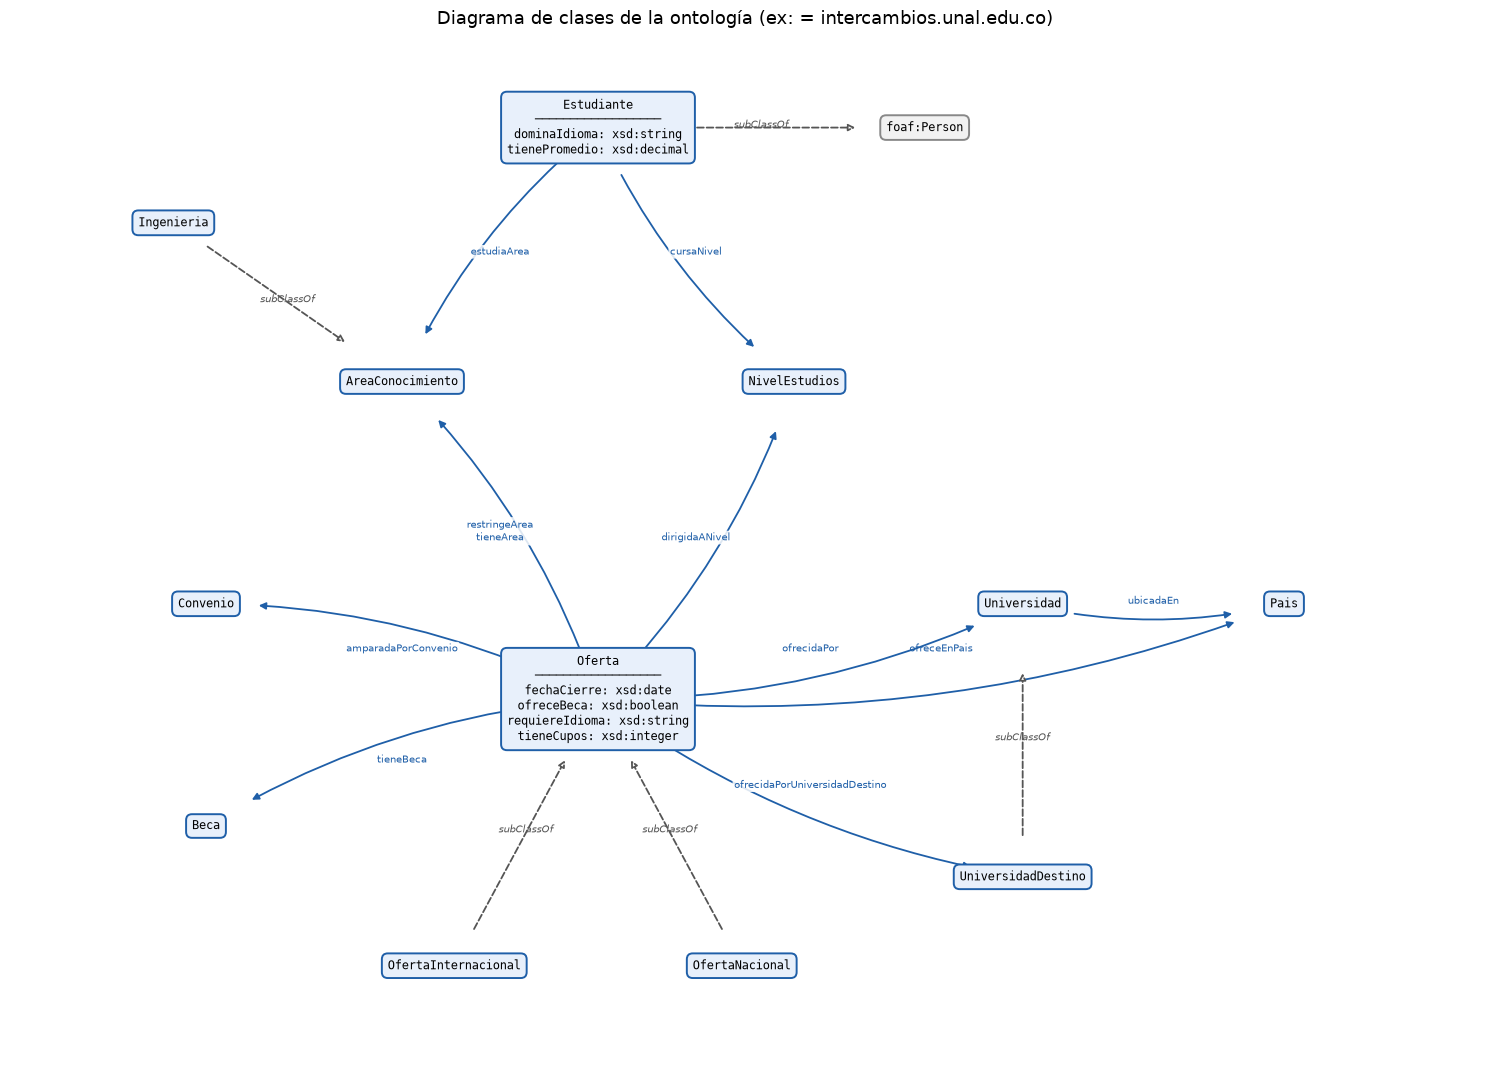

In [5]:
import matplotlib.pyplot as plt
import networkx as nx
from rdflib.namespace import XSD, FOAF

def diagrama_clases(ttl=TTL, archivo="diagrama_clases.png"):
    # Dibuja el diagrama de clases leyendo el esquema del .ttl (clases, subClassOf, domain/range).
    g = cargar_grafo()
    clases = {c for c in g.subjects(RDF.type, RDFS.Class)}
    clases |= {o for o in g.objects(None, RDFS.subClassOf)}

    def nombre(u):
        return qn(u).replace("ex:", "") if str(u).startswith(str(EX)) else g.qname(u)

    atributos, relaciones = {}, {}
    for p in g.subjects(RDF.type, RDF.Property):
        dom, rng = g.value(p, RDFS.domain), g.value(p, RDFS.range)
        if rng is not None and str(rng).startswith(str(XSD)):
            atributos.setdefault(dom, []).append(f"{nombre(p)}: {g.qname(rng)}")
        else:
            relaciones.setdefault((dom, rng), []).append(nombre(p))

    # Posiciones fijas para que el diagrama sea legible; clases nuevas se ubican automáticamente.
    pos = {EX.Oferta: (6, 5), EX.OfertaInternacional: (3.8, 0.8), EX.OfertaNacional: (8.2, 0.8),
           EX.Universidad: (12.5, 6.5), EX.UniversidadDestino: (12.5, 2.2), EX.Pais: (16.5, 6.5),
           EX.AreaConocimiento: (3, 10), EX.NivelEstudios: (9, 10), EX.Ingenieria: (-0.5, 12.5),
           EX.Convenio: (0, 6.5), EX.Beca: (0, 3), EX.Estudiante: (6, 14), FOAF.Person: (11, 14)}
    faltan = [c for c in clases if c not in pos]
    if faltan:
        extra = nx.circular_layout(nx.Graph(faltan), scale=3, center=(17, 12))
        pos.update(extra)

    fig, ax = plt.subplots(figsize=(15, 11))
    for (d, r), props in relaciones.items():
        if d in pos and r in pos:
            ax.annotate("", xy=pos[r], xytext=pos[d],
                        arrowprops=dict(arrowstyle="-|>", color="#1f5fa8", lw=1.3, shrinkA=38, shrinkB=38,
                                        connectionstyle="arc3,rad=0.12"))
            mx, my = (pos[d][0] + pos[r][0]) / 2, (pos[d][1] + pos[r][1]) / 2
            ax.text(mx, my, "\n".join(props), fontsize=7.5, color="#1f5fa8", ha="center",
                    bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))
    for s, o in g.subject_objects(RDFS.subClassOf):
        if s in pos and o in pos:
            ax.annotate("", xy=pos[o], xytext=pos[s],
                        arrowprops=dict(arrowstyle="-|>", color="#555", lw=1.3, ls="--",
                                        shrinkA=30, shrinkB=50, fc="white"))
            mx, my = (pos[s][0] + pos[o][0]) / 2, (pos[s][1] + pos[o][1]) / 2
            ax.text(mx, my, "subClassOf", fontsize=7, color="#555", ha="center", style="italic")
    for c in clases:
        if c not in pos:
            continue
        texto = nombre(c)
        if atributos.get(c):
            texto += "\n" + "─" * 18 + "\n" + "\n".join(sorted(atributos[c]))
        externa = not str(c).startswith(str(EX))
        ax.text(*pos[c], texto, ha="center", va="center", fontsize=8.5, family="monospace",
                bbox=dict(boxstyle="round,pad=0.5", fc="#f2f2f2" if externa else "#e8f0fb",
                          ec="#888" if externa else "#1f5fa8", lw=1.4))
    ax.set_xlim(-3, 19.5); ax.set_ylim(-1, 15.5); ax.axis("off")
    ax.set_title("Diagrama de clases de la ontología (ex: = intercambios.unal.edu.co)", fontsize=13)
    fig.tight_layout()
    fig.savefig(os.path.join(BASE_DIR, archivo), dpi=150)
    plt.show()
    plt.close(fig)

diagrama_clases()

## 2. Lógica difusa (Scikit-Fuzzy)

### 2.1 Idoneidad difusa de una oferta para un estudiante

**Variables y universos de discurso**

| Variable | Tipo | Universo | Valores difusos y función de pertenencia |
|---|---|---|---|
| `promedio` (P.A.P.A.) | entrada | [0, 5] | `bajo` **trapezoidal** (0,0,3.0,3.6) · `medio` **triangular** (3.2,3.8,4.4) · `alto` **trapezoidal** (4.0,4.5,5,5) |
| `nivel_idioma` (MCER → 0-100) | entrada | [0, 100] | `basico` triangular (0,0,45) · `intermedio` triangular (30,55,80) · `avanzado` triangular (65,100,100) |
| `cupos` | entrada | [0, 10] | `pocos` **gaussiana** (μ=1, σ=1.5) · `moderados` gaussiana (μ=5, σ=1.5) · `muchos` gaussiana (μ=10, σ=2) |
| `idoneidad` | salida | [0, 100] | `baja` triangular (0,0,50) · `media` triangular (25,50,75) · `alta` triangular (50,100,100) |

El nivel de idioma se lee del texto de la ontología (`"Inglés B2"`) y se convierte a la escala 0-100 (A1=10, A2=25, B1=45, B2=65, C1=85, C2/nativo=100).

**Modificadores (hedges)**
- **muy** (concentración): μ<sub>muy A</sub>(x) = μ<sub>A</sub>(x)² → `promedio['muy_alto']`. Hace el conjunto más exigente.
- **ligeramente** (dilatación): μ<sub>ligeramente A</sub>(x) = μ<sub>A</sub>(x)<sup>0.5</sup> → `cupos['ligeramente_pocos']`. Hace el conjunto más permisivo.

**Reglas difusas (10)** — operadores: AND = `&` (intersección, mínimo), OR = `|` (unión, máximo), NOT = `~` (complemento, 1 − μ).

| Regla | Antecedente | Consecuente |
|---|---|---|
| R1 | promedio alto **AND** idioma avanzado | idoneidad alta |
| R2 | promedio **muy** alto **AND** cupos pocos | idoneidad alta |
| R3 | promedio bajo **OR** idioma básico | idoneidad baja |
| R4 | promedio medio **AND** cupos pocos | idoneidad baja |
| R5 | promedio medio **AND NOT** cupos pocos | idoneidad media |
| R6 | promedio medio **AND** idioma intermedio | idoneidad media |
| R7 | promedio alto **AND** idioma intermedio **AND** cupos muchos | idoneidad alta |
| R8 | idioma avanzado **AND** cupos **ligeramente** pocos | idoneidad media |
| R9 | **NOT** idioma básico **AND** cupos muchos | idoneidad alta |
| R10 | promedio medio **OR** cupos moderados | idoneidad media |

**Defuzzificación: centroide (justificación).** El centroide calcula el centro de gravedad del área agregada de salida, z* = ∫ μ(z)·z dz / ∫ μ(z) dz. Se eligió porque:
1. **Tiene en cuenta todas las reglas activadas** y su grado de activación, no solo la de mayor pertenencia. Aquí varias reglas suelen dispararse a la vez (p. ej. R5 y R10 empujan a media mientras R1 o R9 empujan a alta), y el resultado debe reflejar ese balance.
2. **Es continuo.** Pequeños cambios en el promedio o en los cupos producen pequeños cambios en el puntaje. Así se pueden **ordenar** las recomendaciones por puntaje, que es justo lo que hace el sistema experto. El método del máximo (MOM) da saltos y empates (en la comparación de abajo devuelve exactamente 50.0, el pico de "media", ignorando la contribución de "baja").
3. El bisector da valores parecidos al centroide pero es menos estándar en inferencia Mamdani y no aporta ventajas para este problema.

La celda imprime la comparación centroide / bisector / MOM para el mismo caso y guarda las gráficas de las funciones de pertenencia (con los modificadores punteados) y de la salida agregada con su centroide.

**Integración:** `ofertas_desde_grafo()` y `perfil_desde_grafo()` leen los datos de entrada del **grafo razonado**, y `resultados_para_experto()` devuelve la lista `{oferta, puntaje, categoria}`. El sistema experto la recibe como hechos `ResultadoDifuso` y la usa en las precondiciones de las reglas r06–r09.

In [6]:
%pip install scikit-fuzzy

In [7]:
import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl

promedio = ctrl.Antecedent(np.arange(0, 5.01, 0.01), 'promedio')
nivel_idioma = ctrl.Antecedent(np.arange(0, 101, 1), 'nivel_idioma')
cupos = ctrl.Antecedent(np.arange(0, 10.01, 0.05), 'cupos')
idoneidad = ctrl.Consequent(np.arange(0, 101, 1), 'idoneidad')

promedio['bajo'] = fuzz.trapmf(promedio.universe, [0, 0, 3.0, 3.6])
promedio['medio'] = fuzz.trimf(promedio.universe, [3.2, 3.8, 4.4])
promedio['alto'] = fuzz.trapmf(promedio.universe, [4.0, 4.5, 5.0, 5.0])

nivel_idioma['basico'] = fuzz.trimf(nivel_idioma.universe, [0, 0, 45])
nivel_idioma['intermedio'] = fuzz.trimf(nivel_idioma.universe, [30, 55, 80])
nivel_idioma['avanzado'] = fuzz.trimf(nivel_idioma.universe, [65, 100, 100])

cupos['pocos'] = fuzz.gaussmf(cupos.universe, 1.0, 1.5)
cupos['moderados'] = fuzz.gaussmf(cupos.universe, 5.0, 1.5)
cupos['muchos'] = fuzz.gaussmf(cupos.universe, 10.0, 2.0)

idoneidad['baja'] = fuzz.trimf(idoneidad.universe, [0, 0, 50])
idoneidad['media'] = fuzz.trimf(idoneidad.universe, [25, 50, 75])
idoneidad['alta'] = fuzz.trimf(idoneidad.universe, [50, 100, 100])

def muy(mf):
    # Concentración: mu_muy(x) = mu(x)^2. Hace el conjunto más estricto.
    return np.power(mf, 2)

def ligeramente(mf):
    # Dilatación: mu_lig(x) = mu(x)^0.5. Hace el conjunto más permisivo.
    return np.power(mf, 0.5)

promedio['muy_alto'] = muy(promedio['alto'].mf)
cupos['ligeramente_pocos'] = ligeramente(cupos['pocos'].mf)

reglas = [

    ctrl.Rule(promedio['alto'] & nivel_idioma['avanzado'], idoneidad['alta'], label='R1'),

    ctrl.Rule(promedio['muy_alto'] & cupos['pocos'], idoneidad['alta'], label='R2'),

    ctrl.Rule(promedio['bajo'] | nivel_idioma['basico'], idoneidad['baja'], label='R3'),

    ctrl.Rule(promedio['medio'] & cupos['pocos'], idoneidad['baja'], label='R4'),

    ctrl.Rule(promedio['medio'] & ~cupos['pocos'], idoneidad['media'], label='R5'),

    ctrl.Rule(promedio['medio'] & nivel_idioma['intermedio'], idoneidad['media'], label='R6'),

    ctrl.Rule(promedio['alto'] & nivel_idioma['intermedio'] & cupos['muchos'],
              idoneidad['alta'], label='R7'),

    ctrl.Rule(nivel_idioma['avanzado'] & cupos['ligeramente_pocos'], idoneidad['media'], label='R8'),

    ctrl.Rule(~nivel_idioma['basico'] & cupos['muchos'], idoneidad['alta'], label='R9'),

    ctrl.Rule(promedio['medio'] | cupos['moderados'], idoneidad['media'], label='R10'),
]

idoneidad.defuzzify_method = 'centroid'
sistema = ctrl.ControlSystem(reglas)

_CATEGORIAS = ['baja', 'media', 'alta']

def categoria_de(puntaje):
    # Devuelve el término de salida con mayor grado de pertenencia para `puntaje`.
    grados = {c: fuzz.interp_membership(idoneidad.universe, idoneidad[c].mf, puntaje)
              for c in _CATEGORIAS}
    return max(grados, key=grados.get), grados

def evaluar(prom, idioma, n_cupos, metodo='centroid'):
    # Ejecuta la inferencia Mamdani para un par (estudiante, oferta).
    idoneidad.defuzzify_method = metodo
    try:
        sim = ctrl.ControlSystemSimulation(sistema)
        sim.input['promedio'] = float(np.clip(prom, 0, 5))
        sim.input['nivel_idioma'] = float(np.clip(idioma, 0, 100))
        sim.input['cupos'] = float(np.clip(n_cupos, 0, 10))
        sim.compute()
    finally:

        idoneidad.defuzzify_method = 'centroid'
    puntaje = float(sim.output['idoneidad'])
    cat, grados = categoria_de(puntaje)
    return {'puntaje': round(puntaje, 2), 'categoria': cat,
            'grados': {k: round(float(v), 3) for k, v in grados.items()}, 'sim': sim}

import re
import unicodedata

_MCER = {'A1': 10, 'A2': 25, 'B1': 45, 'B2': 65, 'C1': 85, 'C2': 100, 'NATIVO': 100}

_IDIOMAS = {'espanol': 'espanol', 'ingles': 'ingles', 'frances': 'frances',
            'aleman': 'aleman', 'portugues': 'portugues', 'italiano': 'italiano',
            'coreano': 'coreano', 'noruego': 'noruego'}

CUPOS_DESCONOCIDOS = 5

def _normalizar(texto):
    # Minúsculas y sin tildes: 'Francés B1' -> 'frances b1'.
    t = unicodedata.normalize('NFD', str(texto).lower())
    return ''.join(c for c in t if unicodedata.category(c) != 'Mn')

def mcer_a_puntaje(nivel):
    # Convierte un nivel MCER ('B2', 'C1', 'nativo'...) a la escala 0-100.
    if nivel is None:
        return 0
    return _MCER.get(str(nivel).strip().upper(), 0)

def idiomas_requeridos(texto_idioma, tipo):
    # Interpreta el texto libre de requisito de idioma de una oferta.
    if not texto_idioma:
        return [('espanol', None)] if tipo == 'nac' else [('ingles', None)]
    resultado = []
    for parte in re.split(r'[/,;]| o ', _normalizar(texto_idioma)):
        idioma = next((v for k, v in _IDIOMAS.items() if k in parte), None)
        if idioma:
            m = re.search(r'\b([abc][12])\b', parte)
            resultado.append((idioma, m.group(1).upper() if m else None))
    return resultado or [('ingles', None)]

def interpretar_dominio(texto):
    # Interpreta un valor de ex:dominaIdioma del estudiante.
    t = _normalizar(texto)
    idioma = next((v for k, v in _IDIOMAS.items() if k in t), None)
    if 'nativo' in t:
        return idioma, 'NATIVO'
    m = re.search(r'\b([abc][12])\b', t)
    return idioma, (m.group(1).upper() if m else None)

def cumple_idioma(requisito, dominio):
    # True si UN idioma que domina el estudiante (texto de ex:dominaIdioma)
    idioma_est, nivel_est = interpretar_dominio(dominio)
    for idioma_req, nivel_req in idiomas_requeridos(requisito, 'int'):
        if idioma_req == idioma_est and mcer_a_puntaje(nivel_est) >= mcer_a_puntaje(nivel_req or 'A1'):
            return True
    return False

def nivel_para_oferta(estudiante, oferta):
    # Nivel (0-100) del estudiante en el idioma que exige la oferta.
    niveles_est = {_normalizar(k): v for k, v in estudiante.get('idiomas', {}).items()}
    opciones = idiomas_requeridos(oferta.get('idioma'), oferta.get('tipo'))
    return max(mcer_a_puntaje(niveles_est.get(idioma)) for idioma, _ in opciones)

def evaluar_oferta(estudiante, oferta_id, oferta):
    # Evalúa una oferta y devuelve el resultado con el detalle de las entradas usadas.
    cupos_oferta = oferta.get('cupos')
    n_cupos = CUPOS_DESCONOCIDOS if cupos_oferta is None else cupos_oferta
    nivel = nivel_para_oferta(estudiante, oferta)
    r = evaluar(estudiante['promedio'], nivel, n_cupos)
    return {'oferta': oferta_id, 'puntaje': r['puntaje'], 'categoria': r['categoria'],
            'entradas': {'promedio': estudiante['promedio'], 'nivel_idioma': nivel,
                         'cupos': n_cupos, 'cupos_estimados': cupos_oferta is None}}

def resultados_para_experto(estudiante, ofertas):
    # Evalúa todas las ofertas para un estudiante.
    return [{k: v for k, v in evaluar_oferta(estudiante, oid, o).items() if k != 'entradas'}
            for oid, o in ofertas.items()]

NS_ONTOLOGIA = 'http://intercambios.unal.edu.co/'

def ofertas_desde_grafo(g, ns=NS_ONTOLOGIA):
    # Lee del grafo RDF ya razonado los datos que necesita la lógica difusa,
    from rdflib import Namespace, RDF
    EX_ = Namespace(ns)
    ofertas = {}
    for s in set(g.subjects(RDF.type, EX_.Oferta)):
        oid = str(s).replace(ns, '')
        cupos_lit = g.value(s, EX_.tieneCupos)
        idioma = g.value(s, EX_.requiereIdioma)
        ofertas[oid] = {
            'tipo': 'nac' if (s, RDF.type, EX_.OfertaNacional) in g else 'int',
            'cupos': int(cupos_lit) if cupos_lit is not None else None,
            'idioma': str(idioma) if idioma is not None else None,
        }
    if not ofertas:

        print('Aviso: no hay ofertas en el grafo (falta razonar?)')
    return dict(sorted(ofertas.items()))

def perfil_desde_grafo(g, estudiante_id, ns=NS_ONTOLOGIA):
    # Lee del grafo el perfil que la lógica difusa necesita de un estudiante
    from rdflib import Namespace
    EX_ = Namespace(ns)
    est = EX_[estudiante_id]
    promedio = g.value(est, EX_.tienePromedio)
    if promedio is None:
        raise ValueError(f"El estudiante '{estudiante_id}' no tiene ex:tienePromedio en la ontología")
    idiomas = {}
    for dom in g.objects(est, EX_.dominaIdioma):
        idioma, nivel = interpretar_dominio(dom)
        if idioma:
            idiomas[idioma] = nivel
    return {'promedio': float(promedio), 'idiomas': idiomas}

def graficar_todo(carpeta='.', ejemplo=(4.3, 70, 3)):
    # Guarda las gráficas de pertenencia (con modificadores) y la salida defuzzific...
    import os
    import matplotlib.pyplot as plt

    def _plot(var, titulo, archivo, destacar=()):
        fig, ax = plt.subplots(figsize=(8, 3.8))
        for nombre, term in var.terms.items():
            estilo = '--' if nombre in destacar else '-'
            ax.plot(var.universe, term.mf, estilo, linewidth=2, label=nombre)
        ax.set_title(titulo)
        ax.set_xlabel(var.label)
        ax.set_ylabel('Grado de pertenencia μ')
        ax.set_ylim(-0.02, 1.05)
        ax.grid(alpha=0.3)
        ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
        fig.tight_layout()
        fig.savefig(os.path.join(carpeta, archivo), dpi=150)
        plt.close(fig)

    _plot(promedio, 'Promedio (trapezoidal / triangular) + modificador "muy"',
          'mf_promedio.png', destacar=('muy_alto',))
    _plot(nivel_idioma, 'Nivel de idioma (triangulares)', 'mf_idioma.png')
    _plot(cupos, 'Cupos disponibles (gaussianas) + modificador "ligeramente"',
          'mf_cupos.png', destacar=('ligeramente_pocos',))
    _plot(idoneidad, 'Idoneidad - salida (triangulares)', 'mf_idoneidad.png')

    r = evaluar(*ejemplo)
    idoneidad.view(sim=r['sim'])
    fig = plt.gcf()
    fig.set_size_inches(8, 3.8)
    plt.title(f'Salida agregada y centroide  (promedio={ejemplo[0]}, idioma={ejemplo[1]}, '
              f'cupos={ejemplo[2]}) → {r["puntaje"]}')
    fig.tight_layout()
    fig.savefig(os.path.join(carpeta, 'salida_centroide.png'), dpi=150)
    plt.close('all')

if __name__ == '__main__':

    from rdflib import Graph, Namespace, RDF
    from owlrl import DeductiveClosure, RDFS_Semantics
    g_demo = Graph()
    g_demo.parse('ontologia.ttl', format='turtle')
    DeductiveClosure(RDFS_Semantics).expand(g_demo)

    OFERTAS = ofertas_desde_grafo(g_demo)
    EXd = Namespace(NS_ONTOLOGIA)
    estudiantes = sorted(str(s).replace(NS_ONTOLOGIA, '')
                         for s in g_demo.subjects(RDF.type, EXd.Estudiante))

    for est_id in estudiantes:
        perfil = perfil_desde_grafo(g_demo, est_id)
        print(f'\nEstudiante {est_id} (promedio {perfil["promedio"]})')
        print(f'{"oferta":34} {"idioma":>6} {"cupos":>6} | {"puntaje":>7}  categoría')
        for oid, o in OFERTAS.items():
            r = evaluar_oferta(perfil, oid, o)
            e = r['entradas']
            cup = f'{e["cupos"]}*' if e['cupos_estimados'] else str(e['cupos'])
            print(f'{oid:34} {e["nivel_idioma"]:>6} {cup:>6} | {r["puntaje"]:>7}  {r["categoria"]}')
    print('* cupos sin definir: se usa', CUPOS_DESCONOCIDOS)

    print('\nComparacion de metodos de defuzzificacion:')
    for m in ['centroid', 'bisector', 'mom']:
        print(f'  {m:9} -> {evaluar(4.3, 25, 4, metodo=m)["puntaje"]}')

    graficar_todo()
    print('\nGraficas guardadas.')



Estudiante est_ana_humanidades (promedio 3.1)
oferta                             idioma  cupos | puntaje  categoría
oferta_eafit_2027_1                   100      9 |   50.33  media
oferta_escuela_colombiana_2027_1      100      5 |   34.85  media
oferta_freie_berlin_2027_1              0      4 |   32.71  baja
oferta_montpellier_2027_1               0      4 |   32.71  baja
oferta_stavanger_2027_1                 0     5* |   33.08  baja
oferta_tolima_2027_1                  100     5* |   34.85  media
oferta_ufps_2027_1                    100     10 |   50.67  media
oferta_unam_2027_1                    100     10 |   50.67  media

Estudiante est_carlos_arquitectura (promedio 3.6)
oferta                             idioma  cupos | puntaje  categoría
oferta_eafit_2027_1                   100      9 |   67.77  alta
oferta_escuela_colombiana_2027_1      100      5 |   50.55  media
oferta_freie_berlin_2027_1             25      4 |   37.95  media
oferta_montpellier_2027_1               


Graficas guardadas.


/Users/aandradev/code/university/IA/Proyecto-IA-Universidades/.venv/lib/python3.14/site-packages/skfuzzy/control/fuzzyvariable.py:125: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


## 3. Sistema experto (Experta) e integración

### 3.1 Clases de hechos

La celda de hechos define **54 clases de `Fact`** en cuatro grupos:
- **Una por clase de la ontología** (12): `Oferta`, `OfertaInternacional`, …, `Estudiante`.
- **Una por propiedad de la ontología** (17): `TieneCupos`, `FechaCierre`, `OfrecidaPor`, …, `DominaIdioma`, con slots tipados (`int`, `date`, `bool`, `float`, `str`).
- **Esquema y cobertura total** (10): `Nombre`/`Descripcion` (anotaciones FOAF/DC/RDFS), `ClaseOntologia`, `PropiedadOntologia`, `Dominio`, `Rango`, `SubClaseDe`, `SubPropiedadDe`, más `EsInstanciaDe`/`Relacion` para cualquier clase o propiedad que se agregue en el futuro.
- **De control y conclusiones**: `Hoy`, `Consulta`, `PerfilCandidato`, `ResultadoDifuso`, `CumpleIdioma`, `Descartada`, `Elegible`, `Procesada`, `Afinidad`, `Recomendacion`, `Advertencia`, `Respaldo`, `SugerenciaBeca`, `Nota`, `Diagnostico`.

> Experta depende de `frozendict`, que usa `collections.Mapping` (eliminado en Python ≥ 3.10). La primera línea de la celda restaura esos alias antes de importar `experta`.

In [8]:
%pip install experta

In [9]:
import collections
import collections.abc
for _name in ("Mapping", "MutableMapping", "Sequence", "Iterable", "Set"):
    if not hasattr(collections, _name):
        setattr(collections, _name, getattr(collections.abc, _name))

from datetime import date
from experta import KnowledgeEngine, Fact, Field, Rule, MATCH, NOT, TEST
from experta.strategies import DepthStrategy
from experta.agenda import Agenda

class Oferta(Fact):               id = Field(str, mandatory=True)
class OfertaInternacional(Fact):  id = Field(str, mandatory=True)
class OfertaNacional(Fact):       id = Field(str, mandatory=True)
class Universidad(Fact):          id = Field(str, mandatory=True)
class UniversidadDestino(Fact):   id = Field(str, mandatory=True)
class Pais(Fact):                 id = Field(str, mandatory=True)
class AreaConocimiento(Fact):     id = Field(str, mandatory=True)
class Ingenieria(Fact):           id = Field(str, mandatory=True)
class NivelEstudios(Fact):        id = Field(str, mandatory=True)
class Convenio(Fact):             id = Field(str, mandatory=True)
class Beca(Fact):                 id = Field(str, mandatory=True)
class Estudiante(Fact):           id = Field(str, mandatory=True)

class TieneCupos(Fact):
    oferta = Field(str, mandatory=True); n = Field(int, mandatory=True)

class FechaCierre(Fact):
    oferta = Field(str, mandatory=True); fecha = Field(date, mandatory=True)

class OfrecidaPor(Fact):
    oferta = Field(str, mandatory=True); uni = Field(str, mandatory=True)

class OfrecidaPorUniversidadDestino(Fact):
    oferta = Field(str, mandatory=True); uni = Field(str, mandatory=True)

class OfreceEnPais(Fact):
    oferta = Field(str, mandatory=True); pais = Field(str, mandatory=True)

class TieneArea(Fact):
    oferta = Field(str, mandatory=True); area = Field(str, mandatory=True)

class DirigidaANivel(Fact):
    oferta = Field(str, mandatory=True); nivel = Field(str, mandatory=True)

class RestringeArea(Fact):
    oferta = Field(str, mandatory=True); area = Field(str, mandatory=True)

class OfreceBeca(Fact):
    oferta = Field(str, mandatory=True); tiene = Field(bool, mandatory=True)

class RequiereIdioma(Fact):
    oferta = Field(str, mandatory=True); nivel = Field(str, mandatory=True)

class UbicadaEn(Fact):
    uni = Field(str, mandatory=True); pais = Field(str, mandatory=True)

class TieneBeca(Fact):
    oferta = Field(str, mandatory=True); beca = Field(str, mandatory=True)

class AmparadaPorConvenio(Fact):
    oferta = Field(str, mandatory=True); convenio = Field(str, mandatory=True)

class EstudiaArea(Fact):
    estudiante = Field(str, mandatory=True); area = Field(str, mandatory=True)

class CursaNivel(Fact):
    estudiante = Field(str, mandatory=True); nivel = Field(str, mandatory=True)

class TienePromedio(Fact):
    estudiante = Field(str, mandatory=True); valor = Field(float, mandatory=True)

class DominaIdioma(Fact):
    estudiante = Field(str, mandatory=True); idioma = Field(str, mandatory=True)

class Nombre(Fact):
    # foaf:name, dct:title o rdfs:label de cualquier recurso.
    id = Field(str, mandatory=True); texto = Field(str, mandatory=True)

class Descripcion(Fact):
    # dct:description de ofertas y becas.
    id = Field(str, mandatory=True); texto = Field(str, mandatory=True)

class EsInstanciaDe(Fact):
    # rdf:type hacia una clase sin Fact propio (p. ej. foaf:Person o una clase nueva).
    id = Field(str, mandatory=True); clase = Field(str, mandatory=True)

class Relacion(Fact):
    # Cualquier predicado sin Fact propio (p. ej. una propiedad nueva agregada al .ttl).
    sujeto = Field(str, mandatory=True); predicado = Field(str, mandatory=True)
    objeto = Field(object, mandatory=True)

class SubClaseDe(Fact):
    # Jerarquía de clases del esquema (rdfs:subClassOf, incluye foaf:Person).
    hija = Field(str, mandatory=True); padre = Field(str, mandatory=True)

class SubPropiedadDe(Fact):
    # Jerarquía de propiedades (rdfs:subPropertyOf).
    hija = Field(str, mandatory=True); padre = Field(str, mandatory=True)

class ClaseOntologia(Fact):
    # Clase declarada en el esquema (x rdf:type rdfs:Class).
    id = Field(str, mandatory=True)

class PropiedadOntologia(Fact):
    # Propiedad declarada o inferida por el razonador (x rdf:type rdf:Property).
    id = Field(str, mandatory=True)

class Dominio(Fact):
    # rdfs:domain de una propiedad.
    propiedad = Field(str, mandatory=True); clase = Field(str, mandatory=True)

class Rango(Fact):
    # rdfs:range de una propiedad (clase del dominio o tipo XSD).
    propiedad = Field(str, mandatory=True); clase = Field(str, mandatory=True)

class Hoy(Fact):
    # Fecha de referencia de la consulta (permite simular distintos 'hoy').
    fecha = Field(date, mandatory=True)

class Consulta(Fact):
    # Único dato de entrada del usuario: QUÉ estudiante (de la ontología) consulta.
    estudiante = Field(str, mandatory=True)

class PerfilCandidato(Fact):
    # Ahora se DERIVA por la regla r00 a partir de los hechos ontológicos
    id = Field(str, mandatory=True)
    nivel_estudios = Field(str, mandatory=True)
    area = Field(str, mandatory=True)

class ResultadoDifuso(Fact):
    # Inyectado por el modulo de logica difusa (Context.md Sec. 5.2).
    oferta = Field(str, mandatory=True)
    puntaje = Field(float, mandatory=True)
    categoria = Field(str, mandatory=True)

class CumpleIdioma(Fact):
    # Derivado por r17: el candidato satisface el requisito de idioma de la oferta.
    oferta = Field(str, mandatory=True); idioma = Field(str, mandatory=True)

class Descartada(Fact):
    # La oferta no aplica para el candidato (también actúa como Lock-Fact del nivel 100).
    oferta = Field(str, mandatory=True); motivo = Field(str, mandatory=True)

class Elegible(Fact):
    # La oferta pasó los filtros y tiene nivel de idoneidad 'alta' o 'media'.
    oferta = Field(str, mandatory=True); nivel = Field(str, mandatory=True)
    puntaje = Field(float, mandatory=True)

class Procesada(Fact):
    # Marca de control (Lock-Fact) para el nivel de prioridad MEDIA.
    oferta = Field(str, mandatory=True)

class Afinidad(Fact):
    # Afinidad parcial entre ingenierías (usa la clase Ingenieria).
    oferta = Field(str, mandatory=True); texto = Field(str, mandatory=True)

class Recomendacion(Fact):
    # Conclusión final del sistema para una oferta.
    oferta = Field(str, mandatory=True)
    prioridad = Field(str, mandatory=True)
    puntaje = Field(float, mandatory=True)
    explicacion = Field(str, mandatory=True)

class Advertencia(Fact):
    # Aviso asociado a una oferta (sin convenio, datos inconsistentes).
    oferta = Field(str, mandatory=True); texto = Field(str, mandatory=True)

class Respaldo(Fact):
    # La oferta está amparada por un convenio de la ontología.
    oferta = Field(str, mandatory=True); texto = Field(str, mandatory=True)

class SugerenciaBeca(Fact):
    # Beca general (no ligada a ninguna oferta) sugerida para una oferta recomendada.
    oferta = Field(str, mandatory=True); beca = Field(str, mandatory=True)
    texto = Field(str, mandatory=True)

class Nota(Fact):
    # Información adicional para una oferta recomendada.
    oferta = Field(str, mandatory=True); texto = Field(str, mandatory=True)

class Diagnostico(Fact):
    # Resultado de las reglas que validan el esquema de la ontología.
    texto = Field(str, mandatory=True)


### 3.2 Traductor Ontología → Sistema Experto

`traducir(g, engine)` recorre **cada triple** del grafo razonado y declara el Fact correspondiente. Los diccionarios `CLASS_TO_FACT`, `PREDICATE_TO_FACT`, `SCHEMA_TO_FACT` y `ANNOTATION_TO_FACT` mapean únicamente **vocabulario** (clases y predicados), nunca individuos ni valores concretos:

| Triple del grafo | Fact generado |
|---|---|
| `x rdf:type C` con `C` clase del dominio | `C(id=x)` (p. ej. `OfertaInternacional(id=...)`) |
| `x rdf:type rdfs:Class` / `rdf:Property` | `ClaseOntologia(id=x)` / `PropiedadOntologia(id=x)` |
| `x rdf:type foaf:Person` (inferido) u otra clase no prevista | `EsInstanciaDe(id=x, clase=...)` |
| `s p o` con `p` propiedad del dominio | Fact tipado (`TieneCupos(oferta, n:int)`, `FechaCierre(oferta, fecha:date)`, …) con conversión XSD → Python |
| `rdfs:domain`, `rdfs:range`, `rdfs:subClassOf`, `rdfs:subPropertyOf` | `Dominio`, `Rango`, `SubClaseDe`, `SubPropiedadDe` |
| `foaf:name`, `dct:title`, `rdfs:label` / `dct:description` | `Nombre` / `Descripcion` |
| cualquier otro predicado (p. ej. uno nuevo agregado al `.ttl`) | `Relacion(sujeto, predicado, objeto)` |

Solo se omiten los **axiomas triviales** que el razonador agrega sobre el propio vocabulario RDF/RDFS/XSD: triples cuyo sujeto no es del dominio (`rdfs:label rdf:type rdf:Property`…), `x rdf:type rdfs:Resource` y la reflexividad `C subClassOf C` / `p subPropertyOf p`. Ninguno describe el dominio. `correr_caso()` imprime el conteo para dejarlo visible en cada ejecución.

In [10]:
from rdflib import Namespace, Literal, URIRef
from rdflib.namespace import RDF, RDFS, XSD, FOAF, DCTERMS

EX = Namespace("http://intercambios.unal.edu.co/")

CLASS_TO_FACT = {
    EX.Oferta: Oferta, EX.OfertaInternacional: OfertaInternacional,
    EX.OfertaNacional: OfertaNacional, EX.Universidad: Universidad,
    EX.UniversidadDestino: UniversidadDestino, EX.Pais: Pais,
    EX.AreaConocimiento: AreaConocimiento, EX.Ingenieria: Ingenieria,
    EX.NivelEstudios: NivelEstudios, EX.Convenio: Convenio,
    EX.Beca: Beca, EX.Estudiante: Estudiante,
}

PREDICATE_TO_FACT = {
    EX.tieneCupos:     (TieneCupos, "oferta", "n"),
    EX.fechaCierre:    (FechaCierre, "oferta", "fecha"),
    EX.ofrecidaPor:    (OfrecidaPor, "oferta", "uni"),
    EX.ofrecidaPorUniversidadDestino: (OfrecidaPorUniversidadDestino, "oferta", "uni"),
    EX.ofreceEnPais:   (OfreceEnPais, "oferta", "pais"),
    EX.tieneArea:      (TieneArea, "oferta", "area"),
    EX.dirigidaANivel: (DirigidaANivel, "oferta", "nivel"),
    EX.restringeArea:  (RestringeArea, "oferta", "area"),
    EX.ofreceBeca:     (OfreceBeca, "oferta", "tiene"),
    EX.requiereIdioma: (RequiereIdioma, "oferta", "nivel"),
    EX.ubicadaEn:      (UbicadaEn, "uni", "pais"),

    EX.tieneBeca:           (TieneBeca, "oferta", "beca"),
    EX.amparadaPorConvenio: (AmparadaPorConvenio, "oferta", "convenio"),
    EX.estudiaArea:         (EstudiaArea, "estudiante", "area"),
    EX.cursaNivel:          (CursaNivel, "estudiante", "nivel"),
    EX.tienePromedio:       (TienePromedio, "estudiante", "valor"),
    EX.dominaIdioma:        (DominaIdioma, "estudiante", "idioma"),
}

ANNOTATION_TO_FACT = {
    FOAF.name: Nombre, DCTERMS.title: Nombre, RDFS.label: Nombre,
    DCTERMS.description: Descripcion,
}

SCHEMA_TO_FACT = {
    RDFS.domain:        (Dominio, "propiedad", "clase"),
    RDFS.range:         (Rango, "propiedad", "clase"),
    RDFS.subClassOf:    (SubClaseDe, "hija", "padre"),
    RDFS.subPropertyOf: (SubPropiedadDe, "hija", "padre"),
}

META_CLASE_TO_FACT = {RDFS.Class: ClaseOntologia, RDF.Property: PropiedadOntologia}

PREFIJOS = (("foaf", FOAF), ("xsd", XSD), ("dct", DCTERMS), ("rdfs", RDFS), ("rdf", RDF))

def nombre_local(uri):
    # ex:algo -> 'algo'; otros vocabularios -> 'foaf:Person', 'xsd:integer'. Puramente mecánico.
    s = str(uri)
    if s.startswith(str(EX)):
        return s[len(str(EX)):]
    for pref, ns in PREFIJOS:
        if s.startswith(str(ns)):
            return f"{pref}:{s[len(str(ns)):]}"
    return s

def es_axioma_trivial(s, p, o):
    # Axiomas que el razonador agrega sobre el propio vocabulario RDF/RDFS/XSD (no describen el dominio).
    return (not es_del_dominio(s)
            or o == RDFS.Resource
            or (s == o and p in (RDFS.subClassOf, RDFS.subPropertyOf)))

def es_del_dominio(uri):
    # True si el URI pertenece al namespace del proyecto (ex:).
    return isinstance(uri, URIRef) and str(uri).startswith(str(EX))

def valor_tipado(literal):
    # Convierte un rdflib.Literal a un tipo Python nativo segun su datatype XSD.
    dt = literal.datatype
    try:
        if dt == XSD.integer:
            return int(literal)
        if dt in (XSD.decimal, XSD.double, XSD.float):
            return float(literal)
        if dt == XSD.date:
            return literal.toPython()
        if dt == XSD.boolean:
            return bool(literal.toPython())
    except (ValueError, TypeError):
        pass
    return str(literal)

def traducir(g, engine):
    # Recorre TODAS las tripletas de `g` (ya razonado) y declara un Fact por cada una.
    c = {"tipos": 0, "propiedades": 0, "anotaciones": 0, "esquema": 0,
         "genericos": 0, "axiomas_rdfs_triviales": 0}
    for s, p, o in g:
        if es_axioma_trivial(s, p, o):
            c["axiomas_rdfs_triviales"] += 1
            continue
        valor = valor_tipado(o) if isinstance(o, Literal) else nombre_local(o)
        if p == RDF.type:
            if o in CLASS_TO_FACT:
                engine.declare(CLASS_TO_FACT[o](id=nombre_local(s))); c["tipos"] += 1
            elif o in META_CLASE_TO_FACT:
                engine.declare(META_CLASE_TO_FACT[o](id=nombre_local(s))); c["esquema"] += 1
            else:
                engine.declare(EsInstanciaDe(id=nombre_local(s), clase=valor)); c["genericos"] += 1
            continue
        if p in PREDICATE_TO_FACT:
            FactCls, slot_sujeto, slot_objeto = PREDICATE_TO_FACT[p]
            try:
                engine.declare(FactCls(**{slot_sujeto: nombre_local(s), slot_objeto: valor}))
                c["propiedades"] += 1
                continue
            except Exception as err:
                print(f"   {nombre_local(p)} con valor inesperado ({err}); se traduce como Relacion")
        elif p in SCHEMA_TO_FACT:
            FactCls, slot_sujeto, slot_objeto = SCHEMA_TO_FACT[p]
            engine.declare(FactCls(**{slot_sujeto: nombre_local(s), slot_objeto: valor})); c["esquema"] += 1
            continue
        elif p in ANNOTATION_TO_FACT and isinstance(o, Literal):
            engine.declare(ANNOTATION_TO_FACT[p](id=nombre_local(s), texto=str(o))); c["anotaciones"] += 1
            continue
        # Cualquier otro predicado (p. ej. uno nuevo en el .ttl) se conserva como relación genérica.
        engine.declare(Relacion(sujeto=nombre_local(s), predicado=nombre_local(p), objeto=valor))
        c["genericos"] += 1
    return c


### 3.3 Motor de reglas, prioridades y resolución de conflictos

**30 reglas** agrupadas en 7 niveles de `salience` que forman 3 fases: **derivar → filtrar/evaluar → generar salida**.

| Salience | Fase | Reglas |
|---|---|---|
| 200 | Derivar perfil desde la ontología | r00, r00b |
| 110 | Derivar cumplimiento de idioma | r17 |
| 100 | Filtros duros de descarte | r01 fecha, r02 cupos, r03 nivel, r04/r05 área, r18 idioma, r24 promedio, r19 calidad de datos |
| 50 | Evaluación con la lógica difusa | r06, r07, r08 (usan `ResultadoDifuso`), r09 afinidad exacta, r20 afinidad entre ingenierías |
| 10 | Generar recomendación | r10 internacional, r11 nacional, r12 con beca |
| 5 | Enriquecer | r14 beca sugerida, r15 convenio, r16 sin convenio, r21 descripción |
| 0 | Reportes y validación del esquema | r13, r22, r23, r25, r26, r27, r28 |

**Estrategia de resolución de conflictos (`EstrategiaConflictos`).** Cuando varias reglas están activadas a la vez, la agenda las ordena por la tupla `(salience, especificidad, recencia)`. Python compara tuplas en orden lexicográfico, así que cada criterio solo desempata al anterior:

1. **Salience (prioridad explícita).** Cada regla declara `salience=N` y gana la de mayor valor. Así los filtros duros (100) se ejecutan antes que la evaluación difusa (50). Si una oferta ya fue descartada por fecha, la regla de elegibilidad no llega a considerarla, porque el hecho `Descartada` ya existe cuando le toca.
2. **Especificidad.** Con igual salience gana la regla con **más condiciones** en su LHS (`len(activation.rule)`), es decir, la más específica. Ejemplo: `r04_area_restringida_general` (5 condiciones) y `r05_area_restringida_exclusiva` (6 condiciones, añade `TieneArea` = misma área) se activan para la misma oferta. Gana r05, que da el diagnóstico más preciso ("oferta EXCLUSIVA del área"), y su `Descartada` bloquea a r04.
3. **Recencia.** Con igual salience y especificidad gana la activación cuyos hechos son **más recientes**: los `factid` ordenados de mayor a menor, comparados lexicográficamente. Ejemplo: dos ofertas vencidas activan `r01`, y se procesa primero la declarada más tarde.

`AgendaConTraza` guarda `(regla, salience, especificidad, recencia)` de cada disparo, y la celda 3.6 demuestra los tres criterios con `assert`.

**Control de bucles (Lock-Fact).** Toda regla que declara un hecho incluye en su LHS un `NOT(...)` sobre ese mismo hecho o sobre un candado:
- `Descartada` actúa como candado del nivel 100: `NOT(Descartada(oferta=o))` en r01–r05, r18 y r24 impide descartar dos veces o que dos filtros compitan.
- `Procesada` es un candado dedicado del nivel 50 (r06–r09): sin él, r07 (media) y r09 (media + afinidad) declararían dos `Elegible` contradictorios para la misma oferta.
- `NOT(Recomendacion(...))`, `NOT(Respaldo(...))`, `NOT(PerfilCandidato(...))`, etc. cumplen el mismo papel en los demás niveles. Sin ellos, cada `declare` reactivaría la regla y el motor entraría en un bucle infinito.

In [11]:
class EstrategiaConflictos(DepthStrategy):
    # Ordena la agenda por (salience, especificidad, recencia).

    def get_key(self, activation):
        # Clave de orden de una activación; la agenda ejecuta primero la clave mayor.
        salience = activation.rule.salience
        especificidad = len(activation.rule)
        recencia = sorted((f['__factid__'] for f in activation.facts), reverse=True)
        return (salience, especificidad, recencia)

class AgendaConTraza(Agenda):
    # Agenda que guarda la secuencia de disparos (regla + clave de resolución).

    def __init__(self):
        super().__init__()
        self.traza = []

    def get_next(self):
        # Saca la siguiente activación y registra su clave de resolución de conflictos.
        act = super().get_next()
        if act is not None:
            sal, esp, rec = act.key
            self.traza.append((act.rule.__name__, sal, esp, rec[:3]))
        return act

SIN_CONVENIO = "sin convenio registrado en la ontología: confirmar convenio vigente con la DRE"

# Política del sistema: promedio mínimo exigido para postularse a movilidad internacional.
PROMEDIO_MINIMO_INTERNACIONAL = 3.5

class SistemaExpertoIntercambios(KnowledgeEngine):
    # Motor de reglas: recibe los Facts de la ontología y de la lógica difusa y recomienda ofertas.

    __strategy__ = EstrategiaConflictos

    def __init__(self):
        super().__init__()
        self.agenda = AgendaConTraza()

    def reset(self, **kwargs):
        # Reinicia la memoria de trabajo y la traza de disparos.
        super().reset(**kwargs)
        self.agenda = AgendaConTraza()

    @Rule(
        Consulta(estudiante=MATCH.e),
        Estudiante(id=MATCH.e),
        CursaNivel(estudiante=MATCH.e, nivel=MATCH.n),
        EstudiaArea(estudiante=MATCH.e, area=MATCH.a),
        NOT(PerfilCandidato(id=MATCH.e)),
        salience=200,
    )
    def r00_perfil_desde_ontologia(self, e, n, a):
        # El perfil del candidato se deriva de la ontología (no se escribe a mano).
        self.declare(PerfilCandidato(id=e, nivel_estudios=n, area=a))

    @Rule(
        Consulta(estudiante=MATCH.e),
        NOT(Estudiante(id=MATCH.e)),
        salience=200,
    )
    def r00b_estudiante_inexistente(self, e):
        # Informa que el estudiante consultado no está en la ontología.
        print(f"   el estudiante '{e}' no existe en la ontologia")

    @Rule(
        Consulta(estudiante=MATCH.e),
        RequiereIdioma(oferta=MATCH.o, nivel=MATCH.req),
        DominaIdioma(estudiante=MATCH.e, idioma=MATCH.dom),
        TEST(lambda req, dom: cumple_idioma(req, dom)),
        NOT(CumpleIdioma(oferta=MATCH.o)),
        salience=110,
    )
    def r17_cumple_idioma(self, o, dom):
        # Deriva que el candidato cumple el requisito de idioma de la oferta.
        self.declare(CumpleIdioma(oferta=o, idioma=dom))

    @Rule(
        Hoy(fecha=MATCH.hoy),
        Oferta(id=MATCH.o),
        FechaCierre(oferta=MATCH.o, fecha=MATCH.f),
        TEST(lambda f, hoy: f < hoy),
        NOT(Descartada(oferta=MATCH.o)),
        salience=100,
    )
    def r01_fecha_vencida(self, o, f):
        # Filtro duro: la convocatoria ya cerró respecto a la fecha de referencia Hoy.
        self.declare(Descartada(oferta=o, motivo=f"convocatoria cerrada (cierre {f})"))

    @Rule(
        Oferta(id=MATCH.o),
        TieneCupos(oferta=MATCH.o, n=0),
        NOT(Descartada(oferta=MATCH.o)),
        salience=100,
    )
    def r02_sin_cupos(self, o):
        # Filtro duro: la oferta no tiene cupos.
        self.declare(Descartada(oferta=o, motivo="sin cupos disponibles"))

    @Rule(
        Oferta(id=MATCH.o),
        PerfilCandidato(nivel_estudios=MATCH.n),
        NivelEstudios(id=MATCH.n),
        NOT(DirigidaANivel(oferta=MATCH.o, nivel=MATCH.n)),
        NOT(Descartada(oferta=MATCH.o)),
        salience=100,
    )
    def r03_nivel_no_ofrecido(self, o, n):
        # Filtro duro: la oferta no está dirigida al nivel de estudios del candidato.
        self.declare(Descartada(oferta=o, motivo=f"no dirigida al nivel '{n}' del candidato"))

    @Rule(
        Oferta(id=MATCH.o),
        RestringeArea(oferta=MATCH.o, area=MATCH.a),
        PerfilCandidato(area=MATCH.ac),
        TEST(lambda ac, a: ac != a),
        NOT(Descartada(oferta=MATCH.o)),
        salience=100,
    )
    def r04_area_restringida_general(self, o, a):
        # Filtro duro: la oferta está restringida a un área distinta a la del candidato.
        self.declare(Descartada(oferta=o, motivo=f"restringida al area '{a}'"))

    @Rule(
        Oferta(id=MATCH.o),
        RestringeArea(oferta=MATCH.o, area=MATCH.a),
        TieneArea(oferta=MATCH.o, area=MATCH.a),
        PerfilCandidato(area=MATCH.ac),
        TEST(lambda ac, a: ac != a),
        NOT(Descartada(oferta=MATCH.o)),
        salience=100,
    )
    def r05_area_restringida_exclusiva(self, o, a):
        # Versión más específica de r04: el área restringida es además el área de la oferta.
        self.declare(Descartada(
            oferta=o,
            motivo=f"oferta EXCLUSIVA del area '{a}' (no solo restringida, es su unica area)"))

    @Rule(
        Consulta(estudiante=MATCH.e),
        Oferta(id=MATCH.o),
        RequiereIdioma(oferta=MATCH.o, nivel=MATCH.req),
        NOT(CumpleIdioma(oferta=MATCH.o)),
        NOT(Descartada(oferta=MATCH.o)),
        salience=100,
    )
    def r18_idioma_insuficiente(self, o, req):
        # Filtro duro: el candidato no alcanza el idioma exigido (usa RequiereIdioma).
        self.declare(Descartada(oferta=o, motivo=f"no cumple el requisito de idioma ({req})"))

    @Rule(
        Consulta(estudiante=MATCH.e),
        TienePromedio(estudiante=MATCH.e, valor=MATCH.v),
        OfertaInternacional(id=MATCH.o),
        TEST(lambda v: v < PROMEDIO_MINIMO_INTERNACIONAL),
        NOT(Descartada(oferta=MATCH.o)),
        salience=100,
    )
    def r24_promedio_insuficiente_internacional(self, o, v):
        # Filtro duro con TienePromedio: la movilidad internacional exige un promedio mínimo.
        self.declare(Descartada(
            oferta=o, motivo=f"promedio {v} menor al mínimo {PROMEDIO_MINIMO_INTERNACIONAL} para movilidad internacional"))

    @Rule(
        OfrecidaPor(oferta=MATCH.o, uni=MATCH.u),
        UbicadaEn(uni=MATCH.u, pais=MATCH.p1),
        OfreceEnPais(oferta=MATCH.o, pais=MATCH.p2),
        TEST(lambda p1, p2: p1 != p2),
        NOT(Advertencia(oferta=MATCH.o, texto="datos inconsistentes")),
        salience=100,
    )
    def r19_ubicacion_inconsistente(self, o, u, p1, p2):
        # Control de calidad con UbicadaEn: la universidad y la oferta deben estar en e...
        self.declare(Advertencia(oferta=o, texto="datos inconsistentes"))
        print(f"   aviso: {o} tiene paises distintos ({p1} vs {p2})")

    @Rule(
        ResultadoDifuso(oferta=MATCH.o, categoria="alta", puntaje=MATCH.p),
        NOT(Descartada(oferta=MATCH.o)),
        NOT(Procesada(oferta=MATCH.o)),
        salience=50,
    )
    def r06_elegible_alta(self, o, p):
        # Usa la lógica difusa: idoneidad alta -> elegible con prioridad alta.
        self.declare(Elegible(oferta=o, nivel="alta", puntaje=p))
        self.declare(Procesada(oferta=o))

    @Rule(
        ResultadoDifuso(oferta=MATCH.o, categoria="media", puntaje=MATCH.p),
        NOT(Descartada(oferta=MATCH.o)),
        NOT(Procesada(oferta=MATCH.o)),
        salience=50,
    )
    def r07_elegible_media(self, o, p):
        # Usa la lógica difusa: idoneidad media -> elegible con prioridad media.
        self.declare(Elegible(oferta=o, nivel="media", puntaje=p))
        self.declare(Procesada(oferta=o))

    @Rule(
        ResultadoDifuso(oferta=MATCH.o, categoria="baja"),
        NOT(Descartada(oferta=MATCH.o)),
        NOT(Procesada(oferta=MATCH.o)),
        salience=50,
    )
    def r08_idoneidad_baja_descarta(self, o):
        # Usa la lógica difusa: idoneidad baja -> se descarta la oferta.
        self.declare(Descartada(oferta=o, motivo="idoneidad difusa baja (perfil/idioma insuficiente)"))
        self.declare(Procesada(oferta=o))

    @Rule(
        ResultadoDifuso(oferta=MATCH.o, categoria="media", puntaje=MATCH.p),
        TieneArea(oferta=MATCH.o, area=MATCH.a),
        PerfilCandidato(area=MATCH.a),
        AreaConocimiento(id=MATCH.a),
        NOT(Descartada(oferta=MATCH.o)),
        NOT(Procesada(oferta=MATCH.o)),
        salience=50,
    )
    def r09_afinidad_area_exacta(self, o, a, p):
        # Idoneidad media pero el área de la oferta coincide con la del candidato: sube a alta.
        self.declare(Elegible(oferta=o, nivel="alta", puntaje=p))
        self.declare(Procesada(oferta=o))
        self.declare(Nota(oferta=o, texto=f"sube a prioridad alta por afinidad exacta de área ({a})"))

    @Rule(
        TieneArea(oferta=MATCH.o, area=MATCH.a2),
        Ingenieria(id=MATCH.a2),
        PerfilCandidato(area=MATCH.ac),
        Ingenieria(id=MATCH.ac),
        TEST(lambda ac, a2: ac != a2),
        NOT(Descartada(oferta=MATCH.o)),
        NOT(Afinidad(oferta=MATCH.o)),
        salience=50,
    )
    def r20_afinidad_ingenieria(self, o, a2, ac):
        # Usa la subclase Ingenieria: afinidad parcial entre ingenierías distintas.
        self.declare(Afinidad(oferta=o, texto=f"afinidad parcial: ambas son ingenierías ({ac} / {a2})"))

    @Rule(
        Elegible(oferta=MATCH.o, nivel=MATCH.nv, puntaje=MATCH.p),
        OfertaInternacional(id=MATCH.o),
        OfrecidaPor(oferta=MATCH.o, uni=MATCH.u),
        Universidad(id=MATCH.u),
        UbicadaEn(uni=MATCH.u, pais=MATCH.pa),
        Pais(id=MATCH.pa),
        Nombre(id=MATCH.u, texto=MATCH.nu),
        Nombre(id=MATCH.pa, texto=MATCH.npa),
        NOT(Recomendacion(oferta=MATCH.o)),
        salience=10,
    )
    def r10_recomendacion_internacional(self, o, nv, p, nu, npa):
        # Recomienda una oferta internacional elegible (usa ofrecidaPor inferida por subPropertyOf).
        self.declare(Recomendacion(
            oferta=o, prioridad=nv, puntaje=p,
            explicacion=f"Intercambio internacional en {npa} con {nu}; idoneidad {nv} ({p})."))

    @Rule(
        Elegible(oferta=MATCH.o, nivel=MATCH.nv, puntaje=MATCH.p),
        OfertaNacional(id=MATCH.o),
        OfrecidaPorUniversidadDestino(oferta=MATCH.o, uni=MATCH.u),
        UniversidadDestino(id=MATCH.u),
        Nombre(id=MATCH.u, texto=MATCH.nu),
        NOT(Recomendacion(oferta=MATCH.o)),
        salience=10,
    )
    def r11_recomendacion_nacional(self, o, nv, p, nu):
        # Recomienda una oferta nacional elegible.
        self.declare(Recomendacion(
            oferta=o, prioridad=nv, puntaje=p,
            explicacion=f"Intercambio nacional con {nu}; idoneidad {nv} ({p})."))

    @Rule(
        Elegible(oferta=MATCH.o, nivel="alta", puntaje=MATCH.p),
        OfreceBeca(oferta=MATCH.o, tiene=True),
        TieneBeca(oferta=MATCH.o, beca=MATCH.b),
        Beca(id=MATCH.b),
        Nombre(id=MATCH.b, texto=MATCH.nb),
        OfrecidaPor(oferta=MATCH.o, uni=MATCH.u),
        Universidad(id=MATCH.u),
        UbicadaEn(uni=MATCH.u, pais=MATCH.pa),
        Pais(id=MATCH.pa),
        Nombre(id=MATCH.u, texto=MATCH.nu),
        NOT(Recomendacion(oferta=MATCH.o)),
        salience=10,
    )
    def r12_recomendacion_con_beca(self, o, p, nb, nu):
        # Recomendación de máxima prioridad: idoneidad alta y la oferta tiene beca propia.
        self.declare(Recomendacion(
            oferta=o, prioridad="alta+beca", puntaje=p,
            explicacion=f"Idoneidad alta con {nu} y BECA '{nb}': prioridad máxima ({p})."))

    @Rule(
        Recomendacion(oferta=MATCH.o),
        AmparadaPorConvenio(oferta=MATCH.o, convenio=MATCH.c),
        Convenio(id=MATCH.c),
        Nombre(id=MATCH.c, texto=MATCH.nc),
        NOT(Respaldo(oferta=MATCH.o)),
        salience=5,
    )
    def r15_respaldo_convenio(self, o, nc):
        # Agrega el convenio que respalda la oferta recomendada.
        self.declare(Respaldo(oferta=o, texto=f"respaldada por: {nc}"))

    @Rule(
        Recomendacion(oferta=MATCH.o),
        NOT(AmparadaPorConvenio(oferta=MATCH.o)),
        NOT(Advertencia(oferta=MATCH.o, texto=SIN_CONVENIO)),
        salience=5,
    )
    def r16_advertencia_sin_convenio(self, o):
        # Avisa que la oferta recomendada no tiene convenio registrado.
        self.declare(Advertencia(oferta=o, texto=SIN_CONVENIO))

    @Rule(
        Recomendacion(oferta=MATCH.o),
        OfertaInternacional(id=MATCH.o),
        NOT(TieneBeca(oferta=MATCH.o)),
        Beca(id=MATCH.b),
        NOT(TieneBeca(beca=MATCH.b)),
        Nombre(id=MATCH.b, texto=MATCH.nb),
        NOT(SugerenciaBeca(oferta=MATCH.o, beca=MATCH.b)),
        salience=5,
    )
    def r14_sugerir_beca_general(self, o, b, nb):
        # Beca de la ontología sugerida para ofertas internacionales sin beca propia.
        self.declare(SugerenciaBeca(oferta=o, beca=b, texto=nb))

    @Rule(
        Recomendacion(oferta=MATCH.o),
        Descripcion(id=MATCH.o, texto=MATCH.d),
        NOT(Nota(oferta=MATCH.o, texto=MATCH.d)),
        salience=5,
    )
    def r21_nota_descripcion(self, o, d):
        # Agrega la descripción (dct:description) de la oferta recomendada.
        self.declare(Nota(oferta=o, texto=d))

    @Rule(Descartada(oferta=MATCH.o, motivo=MATCH.m), Nombre(id=MATCH.o, texto=MATCH.t), salience=0)
    def r13_informe_descarte(self, o, m, t):
        # Reporta cada descarte con el nombre legible de la oferta.
        print(f"   descartada {t}: {m}")

    @Rule(EsInstanciaDe(id=MATCH.i, clase=MATCH.c), SubClaseDe(hija=MATCH.c, padre=MATCH.sup), salience=0)
    def r22_clase_nueva(self, i, c, sup):
        # Reporta individuos de clases no previstas en el código (cobertura total).
        print(f"   nuevo: {i} es un(a) {c}")

    @Rule(Relacion(sujeto=MATCH.s, predicado=MATCH.p, objeto=MATCH.v), salience=0)
    def r23_relacion_nueva(self, s, p, v):
        # Reporta relaciones no previstas en el código (cobertura total).
        print(f"   nuevo: {s} {p} {v}")

    @Rule(
        Consulta(estudiante=MATCH.e),
        Estudiante(id=MATCH.e),
        SubClaseDe(hija="Estudiante", padre=MATCH.sup),
        EsInstanciaDe(id=MATCH.e, clase=MATCH.sup),
        salience=0,
    )
    def r25_candidato_superclase(self, e, sup):
        # Usa la inferencia RDFS Estudiante ⊑ foaf:Person: el candidato también es una persona FOAF.
        self.declare(Diagnostico(texto=f"{e} también es {sup} (inferido por rdfs:subClassOf)"))

    @Rule(
        SubPropiedadDe(hija=MATCH.h, padre=MATCH.p),
        PropiedadOntologia(id=MATCH.h),
        PropiedadOntologia(id=MATCH.p),
        Dominio(propiedad=MATCH.h, clase=MATCH.d),
        Dominio(propiedad=MATCH.p, clase=MATCH.d),
        Rango(propiedad=MATCH.h, clase=MATCH.rh),
        Rango(propiedad=MATCH.p, clase=MATCH.rp),
        SubClaseDe(hija=MATCH.rh, padre=MATCH.rp),
        ClaseOntologia(id=MATCH.rp),
        salience=0,
    )
    def r26_subpropiedad_coherente(self, h, p, d, rh, rp):
        # Valida la jerarquía de propiedades: mismo dominio y rango de la hija ⊑ rango del padre.
        self.declare(Diagnostico(texto=f"{h} ⊑ {p} es coherente (dominio {d}, rango {rh} ⊑ {rp})"))

    @Rule(
        SubPropiedadDe(hija=MATCH.h, padre=MATCH.p),
        Rango(propiedad=MATCH.h, clase=MATCH.rh),
        Rango(propiedad=MATCH.p, clase=MATCH.rp),
        TEST(lambda rh, rp: rh != rp),
        NOT(SubClaseDe(hija=MATCH.rh, padre=MATCH.rp)),
        salience=0,
    )
    def r27_subpropiedad_incoherente(self, h, p, rh, rp):
        # Detecta una subpropiedad cuyo rango no es subclase del rango de la propiedad padre.
        self.declare(Diagnostico(texto=f"{h} ⊑ {p} es INCOHERENTE: {rh} no es subclase de {rp}"))

    @Rule(
        PropiedadOntologia(id=MATCH.p),
        NOT(Dominio(propiedad=MATCH.p)),
        salience=0,
    )
    def r28_propiedad_sin_dominio(self, p):
        # Detecta propiedades usadas en los datos pero sin rdfs:domain en el esquema.
        self.declare(Diagnostico(texto=f"la propiedad {p} se usa sin rdfs:domain declarado en el esquema"))


### 3.4 Ejecución integrada (Ontología + Difuso → Experto)

`correr_caso()` implementa el flujo completo para un estudiante de la ontología:
1. Carga y razona el grafo (una sola vez para todos los escenarios).
2. **Difuso:** lee del grafo el perfil del estudiante y las ofertas, y calcula la idoneidad de cada oferta.
3. **Traductor:** convierte todos los triples del grafo razonado en Facts.
4. Declara `Hoy`, `Consulta` (único dato manual) y los `ResultadoDifuso`.
5. `engine.run()` e imprime las recomendaciones ordenadas por prioridad y puntaje, más el diagnóstico del esquema.

Los cinco escenarios usan estudiantes reales de la ontología y fechas distintas para activar reglas diferentes.

In [12]:
g = Graph()
g.parse("ontologia.ttl", format="turtle")
print("Triples antes de razonar:", len(g))
DeductiveClosure(RDFS_Semantics).expand(g)
print("Triples despues de razonar:", len(g))

ORDEN_PRIORIDAD = {"alta+beca": 3, "alta": 2, "media": 1}

def hechos_de(engine, clase):
    # Lista los hechos de una clase presentes en la memoria del motor.
    return [f for f in engine.facts.values() if isinstance(f, clase)]

def reporte(engine):
    # Imprime las recomendaciones ordenadas (prioridad y puntaje) con sus notas.
    extras = {}
    for clase, etiqueta in ((Respaldo, "respaldo"), (Advertencia, "aviso"),
                            (SugerenciaBeca, "beca sugerida"), (Nota, "nota"), (Afinidad, "afinidad")):
        for f in hechos_de(engine, clase):
            extras.setdefault(f["oferta"], []).append(f"{etiqueta}: {f['texto']}")
    recs = hechos_de(engine, Recomendacion)
    recs.sort(key=lambda f: (ORDEN_PRIORIDAD.get(f["prioridad"], 0), f["puntaje"]), reverse=True)
    print("\nRecomendaciones:")
    if not recs:
        print("  ninguna")
    for i, r in enumerate(recs, 1):
        print(f"  {i}. [{r['prioridad']:9}] {r['explicacion']}")
        for e in extras.get(r["oferta"], []):
            print(f"       - {e}")
    diagnosticos = sorted(f["texto"] for f in hechos_de(engine, Diagnostico))
    if diagnosticos:
        print("\nDiagnóstico del esquema de la ontología:")
        for d in diagnosticos:
            print(f"  - {d}")

def correr_caso(g, hoy, estudiante_id, titulo, verbose=True):
    # Ejecuta el pipeline completo para UN estudiante de la ontología.
    print(f"\n{titulo}  (hoy {hoy})")

    ofertas = ofertas_desde_grafo(g)
    resultados = []
    try:
        perfil = perfil_desde_grafo(g, estudiante_id)
        resultados = resultados_para_experto(perfil, ofertas)
    except ValueError as err:
        print(err)

    engine = SistemaExpertoIntercambios()
    engine.reset()
    stats = traducir(g, engine)
    traducidos = len(g) - stats["axiomas_rdfs_triviales"]
    print(f"Traductor: {traducidos} de {len(g)} triples -> Facts {dict(stats)}")

    engine.declare(Hoy(fecha=hoy))
    engine.declare(Consulta(estudiante=estudiante_id))
    for r in resultados:
        engine.declare(ResultadoDifuso(**r))

    engine.run()
    reporte(engine)
    print(f"({len(engine.facts)} hechos, {len(engine.agenda.traza)} reglas disparadas)")
    return engine

eng_A = correr_caso(g, date(2026, 8, 1), "est_juan_sistemas",
                    "ESCENARIO A: Juan — área, idioma, afinidad y beca")

eng_B = correr_caso(g, date(2026, 9, 20), "est_juan_sistemas",
                    "ESCENARIO B: Juan en otra fecha — convocatorias cerradas (r01)")

eng_C = correr_caso(g, date(2026, 8, 1), "est_carlos_arquitectura",
                    "ESCENARIO C: Carlos (maestría) — nivel no ofrecido (r03)")

eng_D = correr_caso(g, date(2026, 8, 1), "est_maria_matematicas",
                    "ESCENARIO D: María — la MISMA oferta (Stavanger) ahora se recomienda")

eng_E = correr_caso(g, date(2026, 8, 1), "est_ana_humanidades",
                    "ESCENARIO E: Ana — promedio bajo: sin movilidad internacional (r24)")


Triples antes de razonar: 292
Triples despues de razonar: 609

ESCENARIO A: Juan — área, idioma, afinidad y beca  (hoy 2026-08-01)
Traductor: 328 de 609 triples -> Facts {'tipos': 69, 'propiedades': 101, 'anotaciones': 85, 'esquema': 69, 'genericos': 4, 'axiomas_rdfs_triviales': 281}
   descartada Intercambio en Université de Montpellier Paul Valéry: no cumple el requisito de idioma (Francés B1)
   descartada Intercambio en University of Stavanger: oferta EXCLUSIVA del area 'area_matematicas' (no solo restringida, es su unica area)

Recomendaciones:
  1. [alta+beca] Idoneidad alta con Escuela Colombiana de Ingeniería Julio Garavito y BECA 'Crédito-beca ICETEX': prioridad máxima (63.51).
       - respaldo: respaldada por: Convenio SÍGUEME UNAL - Escuela Colombiana de Ingeniería
       - nota: sube a prioridad alta por afinidad exacta de área (area_ingenieria_sistemas)
       - nota: Oferta que incluye explícitamente Ingeniería de Sistemas. Requiere el 50% de los créditos aprobados.
  2.

Traductor: 328 de 609 triples -> Facts {'tipos': 69, 'propiedades': 101, 'anotaciones': 85, 'esquema': 69, 'genericos': 4, 'axiomas_rdfs_triviales': 281}


   descartada Intercambio en la UNAM: convocatoria cerrada (cierre 2026-08-20)
   descartada Intercambio en Universidad del Tolima: convocatoria cerrada (cierre 2026-09-18)
   descartada Intercambio en Universidad EAFIT: convocatoria cerrada (cierre 2026-09-18)
   descartada Intercambio en Université de Montpellier Paul Valéry: no cumple el requisito de idioma (Francés B1)
   descartada Intercambio en University of Stavanger: oferta EXCLUSIVA del area 'area_matematicas' (no solo restringida, es su unica area)

Recomendaciones:
  1. [alta+beca] Idoneidad alta con Escuela Colombiana de Ingeniería Julio Garavito y BECA 'Crédito-beca ICETEX': prioridad máxima (63.51).
       - respaldo: respaldada por: Convenio SÍGUEME UNAL - Escuela Colombiana de Ingeniería
       - nota: sube a prioridad alta por afinidad exacta de área (area_ingenieria_sistemas)
       - nota: Oferta que incluye explícitamente Ingeniería de Sistemas. Requiere el 50% de los créditos aprobados.
  2. [alta     ] Intercambi

Traductor: 328 de 609 triples -> Facts {'tipos': 69, 'propiedades': 101, 'anotaciones': 85, 'esquema': 69, 'genericos': 4, 'axiomas_rdfs_triviales': 281}


   descartada Intercambio en la UNAM: promedio 3.1 menor al mínimo 3.5 para movilidad internacional
   descartada Intercambio en Freie Universität Berlin: promedio 3.1 menor al mínimo 3.5 para movilidad internacional
   descartada Intercambio en Université de Montpellier Paul Valéry: no cumple el requisito de idioma (Francés B1)
   descartada Intercambio en University of Stavanger: oferta EXCLUSIVA del area 'area_matematicas' (no solo restringida, es su unica area)

Recomendaciones:
  1. [media    ] Intercambio nacional con Universidad Francisco de Paula Santander Ocaña; idoneidad media (50.67).
       - aviso: sin convenio registrado en la ontología: confirmar convenio vigente con la DRE
  2. [media    ] Intercambio nacional con Universidad EAFIT; idoneidad media (50.33).
       - aviso: sin convenio registrado en la ontología: confirmar convenio vigente con la DRE
  3. [media    ] Intercambio nacional con Escuela Colombiana de Ingeniería Julio Garavito; idoneidad media (34.85).
     

### 3.5 Pruebas unitarias de reglas

Las 8 ofertas reales no cubren todos los casos (ninguna tiene 0 cupos, ni países inconsistentes, etc.), así que estas reglas se prueban con hechos sintéticos en un motor limpio.

In [13]:
print("Pruebas de reglas:")

def motor_con(*hechos):
    # Crea un motor limpio, declara los hechos sintéticos y lo ejecuta.
    eng = SistemaExpertoIntercambios()
    eng.reset()
    for h in hechos:
        eng.declare(h)
    eng.run()
    return eng

eng = motor_con(Oferta(id="oferta_prueba_cupos"), TieneCupos(oferta="oferta_prueba_cupos", n=0))
ok02 = any(f["oferta"] == "oferta_prueba_cupos" for f in hechos_de(eng, Descartada))
print("r02 sin cupos:", ok02)
assert ok02

eng = motor_con(Oferta(id="oferta_prueba_area"),
                TieneArea(oferta="oferta_prueba_area", area="area_x"),
                RestringeArea(oferta="oferta_prueba_area", area="area_y"),
                PerfilCandidato(id="c", nivel_estudios="nivel_pregrado", area="area_z"))
descartes = hechos_de(eng, Descartada)
ok04 = len(descartes) == 1 and descartes[0]["motivo"].startswith("restringida al area")
print("r04 area restringida:", ok04)
assert ok04

eng = motor_con(ResultadoDifuso(oferta="oferta_prueba_baja", puntaje=20.0, categoria="baja"))
ok08 = any(f["oferta"] == "oferta_prueba_baja" and "idoneidad" in f["motivo"] for f in hechos_de(eng, Descartada))
print("r08 idoneidad baja:", ok08)
assert ok08

eng = motor_con(OfrecidaPor(oferta="oferta_x", uni="uni_x"),
                UbicadaEn(uni="uni_x", pais="pais_a"),
                OfreceEnPais(oferta="oferta_x", pais="pais_b"))
ok19 = any(f["texto"] == "datos inconsistentes" for f in hechos_de(eng, Advertencia))
print("r19 ubicacion inconsistente:", ok19)
assert ok19

eng = motor_con(TieneArea(oferta="oferta_y", area="area_ingenieria_sistemas"),
                Ingenieria(id="area_ingenieria_sistemas"), Ingenieria(id="area_ingenieria_civil"),
                PerfilCandidato(id="c", nivel_estudios="nivel_pregrado", area="area_ingenieria_civil"))
afin = hechos_de(eng, Afinidad)
ok20 = len(afin) == 1
print("r20 afinidad ingenieria:", ok20)
assert ok20

eng = motor_con(Consulta(estudiante="est_no_existe"))
ok00b = not hechos_de(eng, PerfilCandidato)
print("r00b estudiante inexistente:", ok00b)
assert ok00b

eng = motor_con(Consulta(estudiante="est_x"), Estudiante(id="est_x"), TienePromedio(estudiante="est_x", valor=3.2),
                OfertaInternacional(id="oferta_int_x"))
ok24 = any(f["oferta"] == "oferta_int_x" and "promedio" in f["motivo"] for f in hechos_de(eng, Descartada))
print("r24 promedio insuficiente internacional:", ok24)
assert ok24

eng = motor_con(SubPropiedadDe(hija="p_hija", padre="p_padre"),
                Rango(propiedad="p_hija", clase="Beca"), Rango(propiedad="p_padre", clase="Pais"))
ok27 = any("INCOHERENTE" in f["texto"] for f in hechos_de(eng, Diagnostico))
print("r27 subpropiedad incoherente:", ok27)
assert ok27

print("\nTodas las pruebas pasaron.")


Pruebas de reglas:
r02 sin cupos: True
r04 area restringida: True
r08 idoneidad baja: True
   aviso: oferta_x tiene paises distintos (pais_a vs pais_b)
r19 ubicacion inconsistente: True
r20 afinidad ingenieria: True
   el estudiante 'est_no_existe' no existe en la ontologia
r00b estudiante inexistente: True
r24 promedio insuficiente internacional: True
r27 subpropiedad incoherente: True

Todas las pruebas pasaron.


### 3.6 Demostración de los mecanismos de resolución de conflictos

Se verifican con `assert` los tres criterios descritos en 3.3, usando la traza de la agenda.

In [14]:
def mostrar_traza(eng, filtro=None):
    # Imprime la secuencia de disparos: regla, salience, especificidad y hechos más...
    for i, (regla, sal, esp, rec) in enumerate(eng.agenda.traza, 1):
        if filtro is None or any(regla.startswith(f) for f in filtro):
            print(f"   {i:>2}. {regla:32} salience={sal:<4} especificidad={esp:<3} hechos={rec}")

print("1) Salience: gana la regla de mayor prioridad (r05 sobre r07).")
eng = motor_con(Oferta(id="of_s"), TieneArea(oferta="of_s", area="area_mat"),
                RestringeArea(oferta="of_s", area="area_mat"),
                PerfilCandidato(id="c", nivel_estudios="nivel_pregrado", area="area_sis"),
                ResultadoDifuso(oferta="of_s", puntaje=55.0, categoria="media"))
mostrar_traza(eng, ("r05", "r07", "r04"))
assert not hechos_de(eng, Elegible)

print("\n2) Especificidad: con igual salience gana la de mas condiciones (r05 sobre r04).")
mostrar_traza(eng, ("r04", "r05"))
assert [t[0] for t in eng.agenda.traza if t[0].startswith(("r04", "r05"))] == ["r05_area_restringida_exclusiva"]

print("\n3) Recencia: con igual salience y especificidad gana la del hecho mas reciente.")
eng = motor_con(Hoy(fecha=date(2026, 9, 20)),
                Oferta(id="of_vieja"), FechaCierre(oferta="of_vieja", fecha=date(2026, 9, 1)),
                Oferta(id="of_nueva"), FechaCierre(oferta="of_nueva", fecha=date(2026, 9, 2)))
mostrar_traza(eng, ("r01",))
orden = [f["oferta"] for f in sorted(hechos_de(eng, Descartada), key=lambda f: f["__factid__"])]
print("   orden de descarte:", orden)
assert orden == ["of_nueva", "of_vieja"]

print("\n4) Primeros disparos del escenario A:")
for i, (regla, sal, esp, rec) in enumerate(eng_A.agenda.traza[:12], 1):
    print(f"   {i:>2}. {regla:32} salience={sal:<4} especificidad={esp:<3} hechos={rec}")

print("\nLos tres mecanismos quedan evidenciados.")


1) Salience: gana la regla de mayor prioridad (r05 sobre r07).
    1. r05_area_restringida_exclusiva   salience=100  especificidad=6   hechos=[4, 3, 2]

2) Especificidad: con igual salience gana la de mas condiciones (r05 sobre r04).
    1. r05_area_restringida_exclusiva   salience=100  especificidad=6   hechos=[4, 3, 2]

3) Recencia: con igual salience y especificidad gana la del hecho mas reciente.
    1. r01_fecha_vencida                salience=100  especificidad=5   hechos=[5, 4, 1]
    2. r01_fecha_vencida                salience=100  especificidad=5   hechos=[3, 2, 1]
   orden de descarte: ['of_nueva', 'of_vieja']

4) Primeros disparos del escenario A:
    1. r00_perfil_desde_ontologia       salience=200  especificidad=5   hechos=[330, 243, 106]
    2. r17_cumple_idioma                salience=110  especificidad=5   hechos=[330, 304, 59]
    3. r17_cumple_idioma                salience=110  especificidad=5   hechos=[330, 276, 27]
    4. r05_area_restringida_exclusiva   salience=

## 4. Caso de prueba obligatorio del traductor

### 4.1 Nuevo individuo y nueva relación agregados solo en `ontologia.ttl`

Se agrega al archivo `.ttl` (sin tocar el traductor ni el sistema experto) una oferta nacional nueva con su universidad y una propiedad **que no existe** en el código (`ex:ofreceAlojamiento`). Luego se vuelve a razonar, traducir y ejecutar el motor. Se comprueba que:
1. la oferta aparece como Fact `OfertaNacional`;
2. la lógica difusa la evaluó (`ResultadoDifuso`);
3. la propiedad desconocida llegó como `Relacion`;
4. las reglas la procesaron y la recomendaron (`Recomendacion`);
5. la regla de validación r28 detectó que `ofreceAlojamiento` no tiene `rdfs:domain` declarado (el razonador la tipó como `rdf:Property`).

Para la sustentación se puede hacer lo mismo **a mano**: pegar el bloque `NUEVO_INDIVIDUO_TTL` al final de la celda `%%writefile ontologia.ttl`, re-ejecutarla y correr la celda 3.4. La celda de abajo lo automatiza y restaura el `.ttl` al final.

In [15]:
NUEVO_INDIVIDUO_TTL = """
ex:oferta_prueba_2027_1 a ex:OfertaNacional ;
    ex:dirigidaANivel ex:nivel_pregrado ;
    ex:fechaCierre "2026-12-01"^^xsd:date ;
    ex:ofreceEnPais ex:pais_colombia ;
    ex:ofrecidaPorUniversidadDestino ex:uni_prueba_2027_1 ;
    ex:tieneArea ex:area_comun ;
    ex:tieneCupos 3 ;
    ex:ofreceAlojamiento true ;
    dct:title "Oferta de prueba agregada solo en el ttl (sin tocar Python)"@es .

ex:uni_prueba_2027_1 a ex:UniversidadDestino ;
    ex:ubicadaEn ex:pais_colombia ;
    foaf:name "Universidad de Prueba" .
"""

with open("ontologia.ttl", encoding="utf-8") as f:
    TTL_CANONICO = f.read()

try:
    with open("ontologia.ttl", "a", encoding="utf-8") as f:
        f.write(NUEVO_INDIVIDUO_TTL)
    print("Se agrego una oferta nueva solo en ontologia.ttl")

    g2 = Graph()
    g2.parse("ontologia.ttl", format="turtle")
    DeductiveClosure(RDFS_Semantics).expand(g2)

    engine2 = correr_caso(g2, date(2026, 8, 1), "est_juan_sistemas",
                          "PRUEBA OBLIGATORIA: oferta y relación nuevas solo en el .ttl")

    presente = any(f["id"] == "oferta_prueba_2027_1" for f in hechos_de(engine2, OfertaNacional))
    difuso = [f for f in hechos_de(engine2, ResultadoDifuso) if f["oferta"] == "oferta_prueba_2027_1"]
    relacion = [f for f in hechos_de(engine2, Relacion) if f["predicado"] == "ofreceAlojamiento"]
    rec_nueva = [f for f in hechos_de(engine2, Recomendacion) if f["oferta"] == "oferta_prueba_2027_1"]
    diag = [f for f in hechos_de(engine2, Diagnostico) if "ofreceAlojamiento" in f["texto"]]

    print("\nComprobacion:")
    print("  aparece como Fact:", presente)
    print("  la logica difusa la evaluo:", bool(difuso))
    print("  la relacion nueva se tradujo:", bool(relacion))
    print("  las reglas la recomendaron:", bool(rec_nueva))
    print("  r28 detectó la propiedad sin esquema:", bool(diag))
    assert presente and difuso and relacion and rec_nueva and diag
    print("\nLa prueba obligatoria se cumple: el cambio quedo solo en el .ttl.")
finally:
    with open("ontologia.ttl", "w", encoding="utf-8") as f:
        f.write(TTL_CANONICO)
    print("ontologia.ttl restaurado.")


Se agrego una oferta nueva solo en ontologia.ttl

PRUEBA OBLIGATORIA: oferta y relación nuevas solo en el .ttl  (hoy 2026-08-01)


Traductor: 344 de 634 triples -> Facts {'tipos': 73, 'propiedades': 109, 'anotaciones': 87, 'esquema': 70, 'genericos': 5, 'axiomas_rdfs_triviales': 290}
   descartada Intercambio en Université de Montpellier Paul Valéry: no cumple el requisito de idioma (Francés B1)
   descartada Intercambio en University of Stavanger: oferta EXCLUSIVA del area 'area_matematicas' (no solo restringida, es su unica area)
   nuevo: oferta_prueba_2027_1 ofreceAlojamiento True

Recomendaciones:
  1. [alta+beca] Idoneidad alta con Escuela Colombiana de Ingeniería Julio Garavito y BECA 'Crédito-beca ICETEX': prioridad máxima (63.51).
       - respaldo: respaldada por: Convenio SÍGUEME UNAL - Escuela Colombiana de Ingeniería
       - nota: sube a prioridad alta por afinidad exacta de área (area_ingenieria_sistemas)
       - nota: Oferta que incluye explícitamente Ingeniería de Sistemas. Requiere el 50% de los créditos aprobados.
  2. [alta     ] Intercambio internacional en México con Universidad Nacional Aut